In [86]:
import sys, pkgutil
print(sys.executable)              # should point to .venv/bin/python or conda env python
print(sys.version)
print(sorted({m.name for m in pkgutil.iter_modules()} & {"tensorflow","torch","pandas"}))


/opt/anaconda3/bin/python
3.12.2 | packaged by conda-forge | (main, Feb 16 2024, 20:54:21) [Clang 16.0.6 ]
['pandas', 'tensorflow']


In [87]:
#%pip install "tensorflow-macos>=2.16,<2.19" "tensorflow-metal>=1.1"

In [88]:
#%pip install tensorflow_decision_forests wurlitzer

## Import Libraries

In [90]:
import tensorflow as tf
import tensorflow_decision_forests as tfdf
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Set up notebook to display multiple outputs in one cell
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"
from IPython.display import display

# Comment this if the data visualisations doesn't work on your side
%matplotlib inline

In [91]:
print("TensorFlow v" + tf.__version__)
print("TensorFlow Decision Forests v" + tfdf.__version__)

TensorFlow v2.19.0
TensorFlow Decision Forests v1.12.0


# Load Datasets

In [93]:
train_file_path = "/Users/scottkeighley/Desktop/MSDS_422/house-prices-advanced-regression-techniques/train.csv"
dataset_df = pd.read_csv(train_file_path)
print("Full train dataset shape is {}".format(dataset_df.shape))

Full train dataset shape is (1460, 81)


In [94]:
dataset_df.head(3)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500


In [95]:
dataset_df = dataset_df.drop('Id', axis=1)
dataset_df.head(3)

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500


In [96]:
dataset_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 80 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MSSubClass     1460 non-null   int64  
 1   MSZoning       1460 non-null   object 
 2   LotFrontage    1201 non-null   float64
 3   LotArea        1460 non-null   int64  
 4   Street         1460 non-null   object 
 5   Alley          91 non-null     object 
 6   LotShape       1460 non-null   object 
 7   LandContour    1460 non-null   object 
 8   Utilities      1460 non-null   object 
 9   LotConfig      1460 non-null   object 
 10  LandSlope      1460 non-null   object 
 11  Neighborhood   1460 non-null   object 
 12  Condition1     1460 non-null   object 
 13  Condition2     1460 non-null   object 
 14  BldgType       1460 non-null   object 
 15  HouseStyle     1460 non-null   object 
 16  OverallQual    1460 non-null   int64  
 17  OverallCond    1460 non-null   int64  
 18  YearBuil

## Housing Price Distribution

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


/var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/ipykernel_47122/3430012634.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(dataset_df['SalePrice'], color='g', bins=100, hist_kws={'alpha': 0.4});


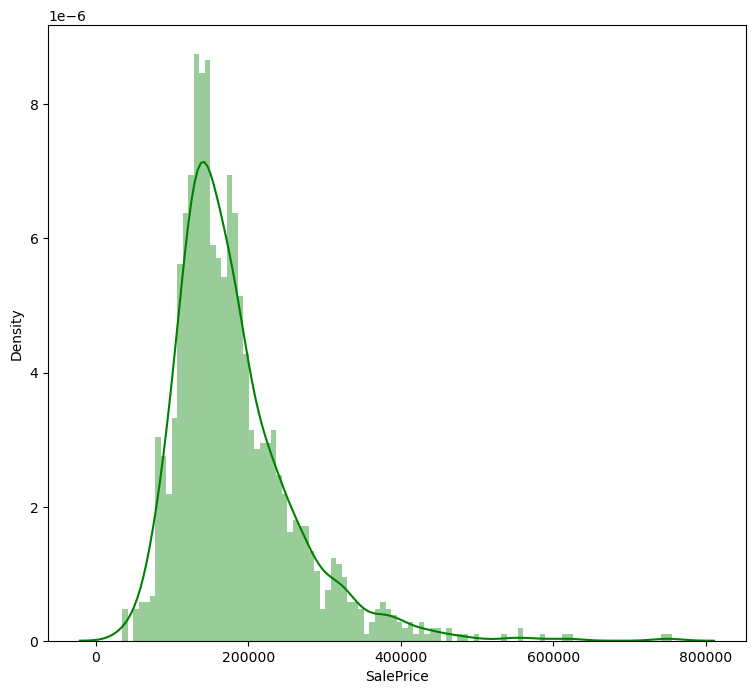

In [98]:
print(dataset_df['SalePrice'].describe())
plt.figure(figsize=(9, 8))
sns.distplot(dataset_df['SalePrice'], color='g', bins=100, hist_kws={'alpha': 0.4});

## Numerical Data Distribution

In [100]:
list(set(dataset_df.dtypes.tolist()))

[dtype('O'), dtype('float64'), dtype('int64')]

In [101]:
df_num = dataset_df.select_dtypes(include = ['float64', 'int64'])
df_num.head()

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
0,60,65.0,8450,7,5,2003,2003,196.0,706,0,...,0,61,0,0,0,0,0,2,2008,208500
1,20,80.0,9600,6,8,1976,1976,0.0,978,0,...,298,0,0,0,0,0,0,5,2007,181500
2,60,68.0,11250,7,5,2001,2002,162.0,486,0,...,0,42,0,0,0,0,0,9,2008,223500
3,70,60.0,9550,7,5,1915,1970,0.0,216,0,...,0,35,272,0,0,0,0,2,2006,140000
4,60,84.0,14260,8,5,2000,2000,350.0,655,0,...,192,84,0,0,0,0,0,12,2008,250000


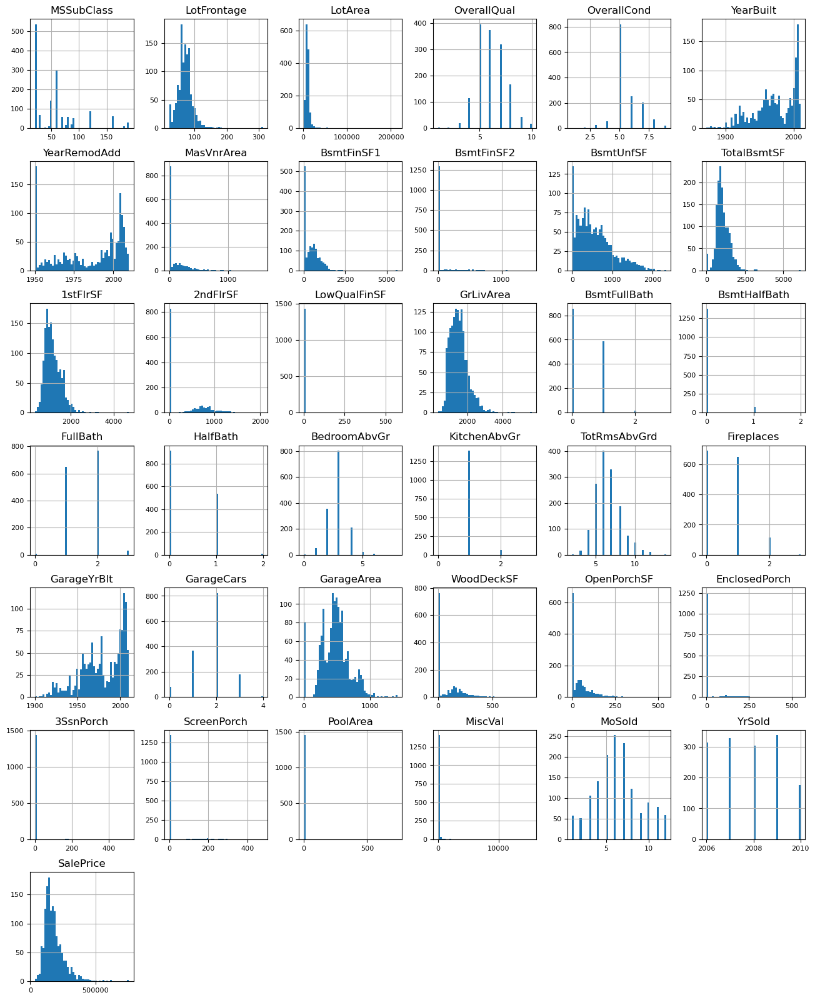

In [102]:
df_num.hist(figsize=(16, 20), bins=50, xlabelsize=8, ylabelsize=8);

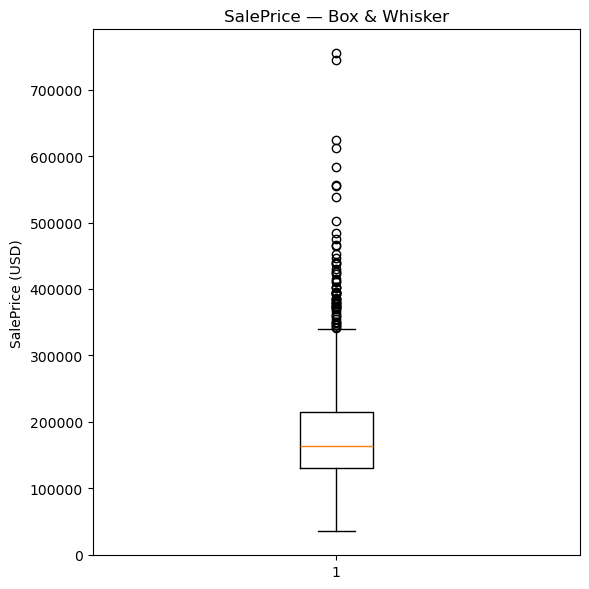

In [103]:
import matplotlib.pyplot as plt

# Ensure the column exists and is numeric
sp = dataset_df["SalePrice"].dropna()

plt.figure(figsize=(6, 6))
plt.boxplot(sp, vert=True, showfliers=True) 
plt.title("SalePrice — Box & Whisker")
plt.ylabel("SalePrice (USD)")
plt.tight_layout()
plt.show();

In [104]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = dataset_df.copy()

def corr_summary(x, y):
    """Print Pearson and Spearman correlations (drop NA & align indices)."""
    data = pd.DataFrame({"x": x, "y": y}).dropna()
    pearson = data["x"].corr(data["y"], method="pearson")
    spearman = data["x"].corr(data["y"], method="spearman")
    print(f"n={len(data)} | Pearson r={pearson:.3f} | Spearman ρ={spearman:.3f}")

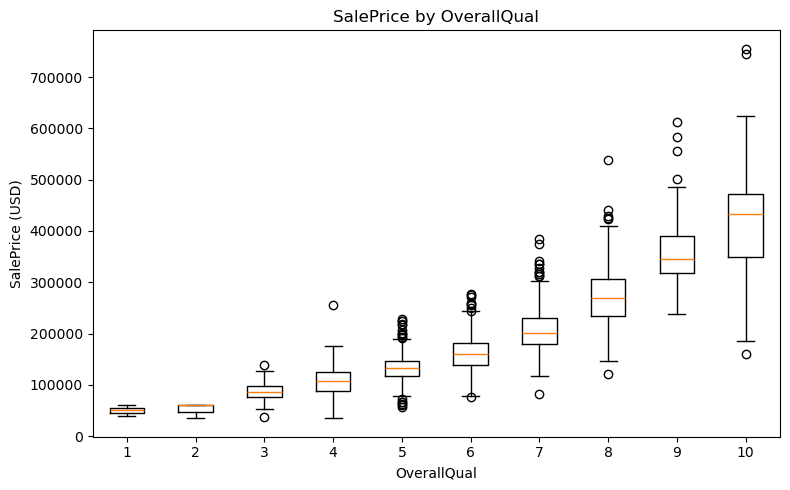

n=1460 | Pearson r=0.791 | Spearman ρ=0.810
             Median_SalePrice
OverallQual                  
1                     50150.0
2                     60000.0
3                     86250.0
4                    108000.0
5                    133000.0
6                    160000.0
7                    200141.0
8                    269750.0
9                    345000.0
10                   432390.0


In [105]:
y = df["SalePrice"]
x = df["OverallQual"]

# Boxplot by quality (categorical on x)
groups = [y[x == q].dropna() for q in sorted(x.dropna().unique())]

plt.figure(figsize=(8, 5))
plt.boxplot(groups, showfliers=True)
plt.title("SalePrice by OverallQual")
plt.xlabel("OverallQual")
plt.ylabel("SalePrice (USD)")
plt.xticks(ticks=range(1, len(groups)+1), labels=sorted(x.dropna().unique()))
plt.tight_layout()
plt.show()

# Correlations (treat OverallQual as ordinal numeric)
corr_summary(x, y)

# Median table (quick effect size by level)
med_table = (
    df.groupby("OverallQual")["SalePrice"]
      .median()
      .rename("Median_SalePrice")
      .to_frame()
      .sort_index()
)
print(med_table.head(10));

<Figure size 700x500 with 0 Axes>

Text(0.5, 1.0, 'SalePrice vs. GrLivArea')

Text(0.5, 0, 'GrLivArea (sq ft)')

Text(0, 0.5, 'SalePrice (USD)')

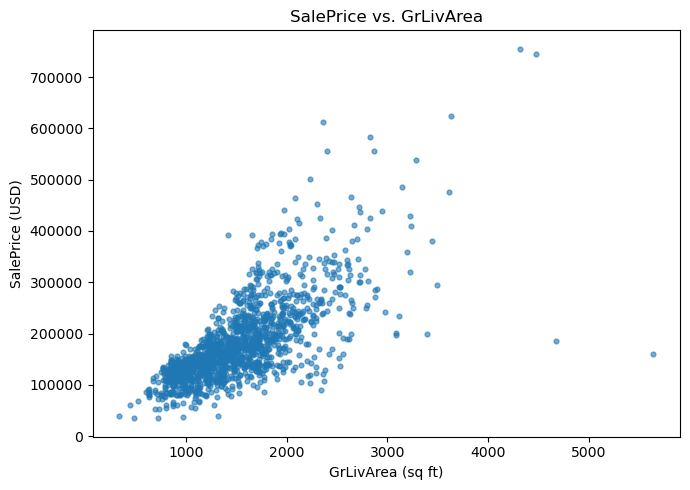

<Figure size 700x500 with 0 Axes>

Text(0.5, 1.0, 'SalePrice vs. GrLivArea (with linear fit)')

Text(0.5, 0, 'GrLivArea (sq ft)')

Text(0, 0.5, 'SalePrice (USD)')

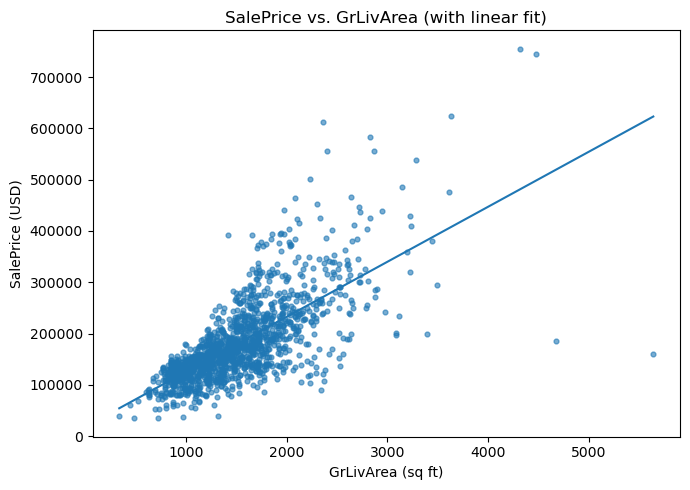

n=1460 | Pearson r=0.709 | Spearman ρ=0.731


<Figure size 700x500 with 0 Axes>

Text(0.5, 1.0, 'log(SalePrice) vs. log(GrLivArea)')

Text(0.5, 0, 'log(1 + GrLivArea)')

Text(0, 0.5, 'log(1 + SalePrice)')

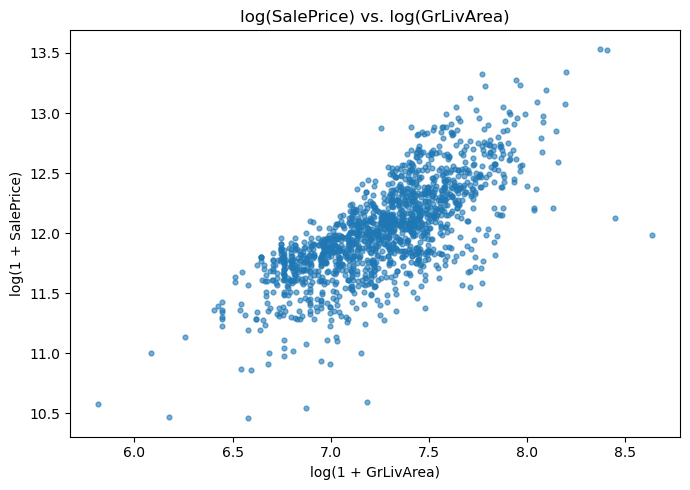

Log-space correlations:
n=1460 | Pearson r=0.730 | Spearman ρ=0.731


In [106]:
x = df["GrLivArea"]
y = df["SalePrice"]

# Basic scatter
plt.figure(figsize=(7, 5))
plt.scatter(x, y, s=12, alpha=0.6)
plt.title("SalePrice vs. GrLivArea")
plt.xlabel("GrLivArea (sq ft)")
plt.ylabel("SalePrice (USD)")
plt.tight_layout()
plt.show()

# Add a simple linear fit line (least squares)
mask = x.notna() & y.notna()
coeffs = np.polyfit(x[mask], y[mask], deg=1)
xline = np.linspace(x[mask].min(), x[mask].max(), 200)
yline = coeffs[0] * xline + coeffs[1]

plt.figure(figsize=(7, 5))
plt.scatter(x, y, s=12, alpha=0.6)
plt.plot(xline, yline)
plt.title("SalePrice vs. GrLivArea (with linear fit)")
plt.xlabel("GrLivArea (sq ft)")
plt.ylabel("SalePrice (USD)")
plt.tight_layout()
plt.show();

# Correlations (linear + rank)
corr_summary(x, y)

# log-transform (often tightens relationship)
x_log = np.log1p(x)
y_log = np.log1p(y)
plt.figure(figsize=(7, 5))
plt.scatter(x_log, y_log, s=12, alpha=0.6)
plt.title("log(SalePrice) vs. log(GrLivArea)")
plt.xlabel("log(1 + GrLivArea)")
plt.ylabel("log(1 + SalePrice)")
plt.tight_layout()
plt.show();

print("Log-space correlations:")
corr_summary(x_log, y_log)


<Figure size 700x500 with 0 Axes>

Text(0.5, 1.0, 'SalePrice vs. TotalBsmtSF')

Text(0.5, 0, 'TotalBsmtSF (sq ft)')

Text(0, 0.5, 'SalePrice (USD)')

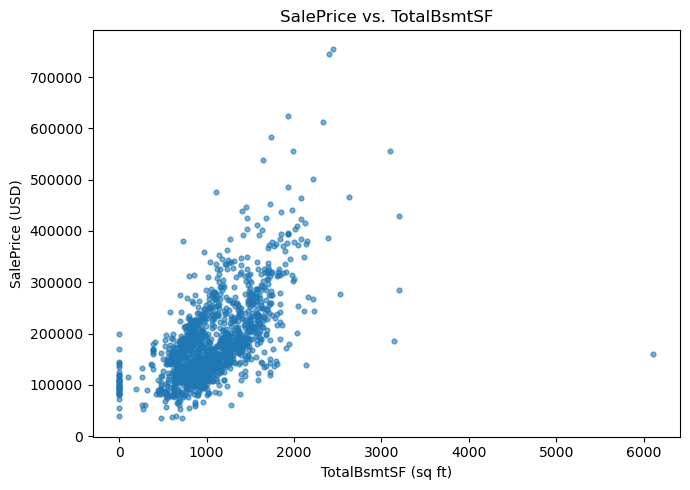

n=1460 | Pearson r=0.614 | Spearman ρ=0.603


<Figure size 700x500 with 0 Axes>

Text(0.5, 1.0, 'SalePrice vs. TotalBsmtSF (non-zero basements)')

Text(0.5, 0, 'TotalBsmtSF (sq ft)')

Text(0, 0.5, 'SalePrice (USD)')

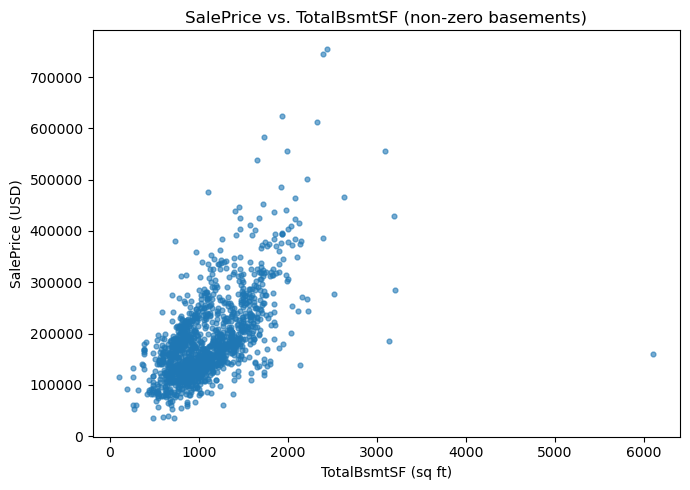

Non-zero basements only:
n=1423 | Pearson r=0.610 | Spearman ρ=0.583


<Figure size 700x500 with 0 Axes>

Text(0.5, 1.0, 'log(SalePrice) vs. log(TotalBsmtSF) (non-zero)')

Text(0.5, 0, 'log(1 + TotalBsmtSF)')

Text(0, 0.5, 'log(1 + SalePrice)')

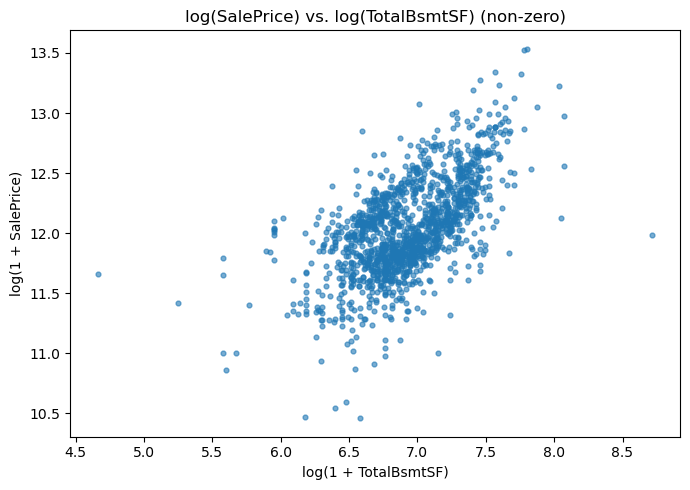

Log-space (non-zero):
n=1423 | Pearson r=0.605 | Spearman ρ=0.583


In [107]:
x = df["TotalBsmtSF"]
y = df["SalePrice"]

# Base scatter
plt.figure(figsize=(7, 5))
plt.scatter(x, y, s=12, alpha=0.6)
plt.title("SalePrice vs. TotalBsmtSF")
plt.xlabel("TotalBsmtSF (sq ft)")
plt.ylabel("SalePrice (USD)")
plt.tight_layout()
plt.show()

corr_summary(x, y)

# exclude zero basements to see linear trend among non-zeros
nz = x > 0
plt.figure(figsize=(7, 5))
plt.scatter(x[nz], y[nz], s=12, alpha=0.6)
plt.title("SalePrice vs. TotalBsmtSF (non-zero basements)")
plt.xlabel("TotalBsmtSF (sq ft)")
plt.ylabel("SalePrice (USD)")
plt.tight_layout()
plt.show()

print("Non-zero basements only:")
corr_summary(x[nz], y[nz])

# log-space among non-zeros
x_log = np.log1p(x[nz])
y_log = np.log1p(y[nz])
plt.figure(figsize=(7, 5))
plt.scatter(x_log, y_log, s=12, alpha=0.6)
plt.title("log(SalePrice) vs. log(TotalBsmtSF) (non-zero)")
plt.xlabel("log(1 + TotalBsmtSF)")
plt.ylabel("log(1 + SalePrice)")
plt.tight_layout()
plt.show()

print("Log-space (non-zero):")
corr_summary(x_log, y_log)

## Size x Quality

Quality amplifies the value of square footage

In [109]:
df = dataset_df.copy()

# centered quality so 0 ≈ average quality (5–6)
q = (df["OverallQual"] - df["OverallQual"].median())

df["QualAdj_LivArea"]   = df["GrLivArea"] * (1 + 0.08*q)        # ~8% per quality notch
df["QualAdj_TotArea"]   = (df["GrLivArea"] + df["TotalBsmtSF"]) * (1 + 0.08*q)
df["QualSq_LivArea"]    = df["GrLivArea"] * (df["OverallQual"]**2)  # nonlinear variant


## Finished space focus

Finished area tends to price stronger than unfinished

In [111]:
df["FinishedSF"] = (
    df["GrLivArea"] 
    + df["BsmtFinSF1"].fillna(0) 
    + df["BsmtFinSF2"].fillna(0)
)
df["FinishedShare"] = df["FinishedSF"] / (df["GrLivArea"] + df["TotalBsmtSF"]).replace(0, np.nan)


## Bathrooms & utility

Bathrooms capture livability better than simple room counts

In [113]:
df["TotalBaths"] = (
    df["FullBath"] 
    + 0.5*df["HalfBath"] 
    + df["BsmtFullBath"] 
    + 0.5*df["BsmtHalfBath"]
)
df["Baths_per_1000sf"] = df["TotalBaths"] / (df["GrLivArea"]/1000)


## Age & condition

Price usually declines with age, but remodels offset it

In [115]:
sale_year = df["YrSold"]
df["HouseAge"]      = sale_year - df["YearBuilt"]
df["YearsSinceReno"]= sale_year - df["YearRemodAdd"]
df["IsRemodeled"]   = (df["YearRemodAdd"] > df["YearBuilt"]).astype(int)

# Interaction: newer + higher quality
df["NewerHighQual"] = (-(df["HouseAge"])) * df["OverallQual"]


## Garage value

Capacity often matters more than raw square footage

In [117]:
df["GarageScore"] = (
    1.0*df["GarageCars"] 
    + 0.001*df["GarageArea"]            # small tie-breaker
)
df["HasGarage"] = (df["GarageCars"] > 0).astype(int)


## Outdoor/amenity bundle

Porches and decks have small, additive effects

In [119]:
df["PorchDeckSF"] = (
    df["WoodDeckSF"] + df["OpenPorchSF"] + df["EnclosedPorch"] 
    + df["3SsnPorch"] + df["ScreenPorch"]
)
df["AmenityCount"] = (
    (df["Fireplaces"]>0).astype(int)
    + (df["PorchDeckSF"]>0).astype(int)
    + (df["PoolArea"]>0).astype(int)
)


## Neighborhood signal (leak-safe target encoding)

Neighborhood is powerful but high-cardinality. Use out-of-fold target means to avoid leakage

In [121]:
from sklearn.model_selection import KFold
import numpy as np
import pandas as pd

def kfold_target_encode(frame, col, target="SalePrice", n_splits=5, noise=0.0):
    out = pd.Series(index=frame.index, dtype=float)
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    for tr, te in kf.split(frame):
        means = frame.iloc[tr].groupby(col)[target].mean()
        out.iloc[te] = frame.iloc[te][col].map(means)
    # global prior for unseen levels
    prior = frame[target].mean()
    out = out.fillna(prior)
    if noise:
        out *= (1 + noise*np.random.randn(len(out)))
    return out

df["NBH_price_oof"] = kfold_target_encode(df, "Neighborhood")


## Seasonality of sale

In some markets, month matters

In [123]:
df["Season_Flag"] = pd.cut(
    df["MoSold"], bins=[0,2,5,8,11,12], labels=["Jan-Feb","Mar-May","Jun-Aug","Sep-Nov","Dec"], right=True
)
# One-hot encode later, or target encode like Neighborhood.


## Ratios & sanity checks

Ratios stabilize scale and reduce heteroscedasticity

In [125]:
df["Price_per_SF_proxy"] = df["SalePrice"] / df["GrLivArea"]  # use only for EDA, NOT as a model input with SalePrice
df["RoomsPer1000SF"]     = df["TotRmsAbvGrd"] / (df["GrLivArea"]/1000)
df["BedsPerBath"]        = df["BedroomAbvGr"]/df["TotalBaths"].replace(0,np.nan)


## Transformations that help most models

In [127]:
for col in ["SalePrice","GrLivArea","FinishedSF","TotalBsmtSF","PorchDeckSF"]:
    df[f"log1p_{col}"] = np.log1p(df[col].clip(lower=0))


In [128]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

y = np.log1p(df["SalePrice"])  # model log-price
num_feats = [
    "GrLivArea","OverallQual","TotalBsmtSF","FinishedSF","FinishedShare",
    "TotalBaths","GarageScore","PorchDeckSF","NBH_price_oof",
    "QualAdj_LivArea","QualAdj_TotArea","NewerHighQual"
]
X = df[num_feats].fillna(0)

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0))
])
scores = cross_val_score(pipe, X, y, cv=5, scoring="r2")
print("CV R^2 (mean±std):", scores.mean().round(3), "±", scores.std().round(3))


CV R^2 (mean±std): 0.846 ± 0.022


In [129]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# assume your DataFrame is dataset_df
y = dataset_df[["SalePrice"]]   # keep as 2D for sklearn

# --- Min-Max Scaling (scales to [0,1]) ---
minmax_scaler = MinMaxScaler()
y_minmax = minmax_scaler.fit_transform(y)

# --- Standard Scaling (z-score: mean=0, std=1) ---
standard_scaler = StandardScaler()
y_standard = standard_scaler.fit_transform(y)

# Put back into a DataFrame for readability
scaled_y = pd.DataFrame({
    "SalePrice": y["SalePrice"].values,
    "SalePrice_minmax": y_minmax.flatten(),
    "SalePrice_standard": y_standard.flatten()
})

print(scaled_y.head())


   SalePrice  SalePrice_minmax  SalePrice_standard
0     208500          0.241078            0.347273
1     181500          0.203583            0.007288
2     223500          0.261908            0.536154
3     140000          0.145952           -0.515281
4     250000          0.298709            0.869843


## RandomForestModel

## Prepare the dataset

This dataset contains a mix of numeric, categorical and missing features. TF-DF supports all these feature types natively, and no preprocessing is required. This is one advantage of tree-based models, making them a great entry point to Tensorflow and ML

In [132]:
import numpy as np

def split_dataset(dataset, test_ratio=0.30):
    test_indices = np.random.rand(len(dataset)) < test_ratio
    return dataset[~test_indices], dataset[test_indices]

train_ds_pd, valid_ds_pd = split_dataset(dataset_df) # changed from dataset_df to df
print("{} examples in training, {} examples in testing.".format(
    len(train_ds_pd), len(valid_ds_pd)))

1036 examples in training, 424 examples in testing.


In [133]:
label = 'SalePrice'
train_ds = tfdf.keras.pd_dataframe_to_tf_dataset(train_ds_pd, label=label, task = tfdf.keras.Task.REGRESSION)
valid_ds = tfdf.keras.pd_dataframe_to_tf_dataset(valid_ds_pd, label=label, task = tfdf.keras.Task.REGRESSION)

## Select a Model

There are several tree-based models for you to choose from:
- RandomForestModel
- GradientBoostedTreesModel
- CartModel
- DistributedGradientBoostedTreesModel

We'll work with a Random Forest. This is the most well-known of the Decision Forest training algorithms. 

A Random Forest is a collection of decision trees, each trained independently on a random subset of the training dataset (sampled with replacement). The algorithm is unique in that it is robust to overfitting, and easy to use. 

In [135]:
tfdf.keras.get_all_models()

[tensorflow_decision_forests.keras.RandomForestModel,
 tensorflow_decision_forests.keras.GradientBoostedTreesModel,
 tensorflow_decision_forests.keras.CartModel,
 tensorflow_decision_forests.keras.DistributedGradientBoostedTreesModel]

## Create a Random Forest

In [137]:
rf = tfdf.keras.RandomForestModel(task = tfdf.keras.Task.REGRESSION)
rf.compile(metrics=["mse"]) # optional, you can use this to include a list of eval metrics

Use /var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/tmpm5kcnobb as temporary training directory


## Train the Model

We will train the model using a one-liner

In [139]:
rf.fit(x=train_ds)

Reading training dataset...
Training dataset read in 0:00:00.359385. Found 1036 examples.
Training model...


I0000 00:00:1759286360.874492 13973300 kernel.cc:782] Start Yggdrasil model training
I0000 00:00:1759286360.874507 13973300 kernel.cc:783] Collect training examples
I0000 00:00:1759286360.874511 13973300 kernel.cc:795] Dataspec guide:
column_guides {
  column_name_pattern: "^__LABEL$"
  type: NUMERICAL
}
default_column_guide {
  categorial {
    max_vocab_count: 2000
  }
  discretized_numerical {
    maximum_num_bins: 255
  }
}
ignore_columns_without_guides: false
detect_numerical_as_discretized_numerical: false

I0000 00:00:1759286360.874612 13973300 kernel.cc:401] Number of batches: 2
I0000 00:00:1759286360.874615 13973300 kernel.cc:402] Number of examples: 1036
I0000 00:00:1759286360.875359 13973300 data_spec_inference.cc:354] 1 item(s) have been pruned (i.e. they are considered out of dictionary) for the column BsmtCond (3 item(s) left) because min_value_count=5 and max_number_of_unique_values=2000
I0000 00:00:1759286360.875366 13973300 data_spec_inference.cc:354] 2 item(s) have be

Model trained in 0:00:00.389085
Compiling model...


I0000 00:00:1759286361.116886 13985351 kernel.cc:926] Export model in log directory: /var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/tmpm5kcnobb with prefix fe9d4f0660b74d5e
I0000 00:00:1759286361.144491 13985351 kernel.cc:944] Save model in resources
I0000 00:00:1759286361.146041 13973300 abstract_model.cc:921] Model self evaluation:
Number of predictions (without weights): 1036
Number of predictions (with weights): 1036
Task: REGRESSION
Label: __LABEL

RMSE: 28377.3 CI95[X2][27206.4 29654.3]
Default RMSE: : 76361.9

2025-09-30 19:39:21.171238: I tensorflow_decision_forests/tensorflow/ops/inference/kernel.cc:1206] Loading model from path /var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/tmpm5kcnobb/model/ with prefix fe9d4f0660b74d5e
I0000 00:00:1759286361.256887 13973300 decision_forest.cc:808] Model loaded with 300 root(s), 98556 node(s), and 73 input feature(s).
I0000 00:00:1759286361.256914 13973300 abstract_model.cc:1439] Engine "RandomForestOptPred" built
2025-09-30 19:39:21.256

Model compiled.


## Visualize the Model

One benefit of tree-based models is that you can easily visualize them. The default number of trees used in the Random Forest is 300. We can select a tree to display below.

In [141]:
tfdf.model_plotter.plot_model_in_colab(rf, tree_idx=0, max_depth=3)

## Evaluate the model on the Out of bag (OOB) data and the validation dataset

Before training the dataset we have manually separated 20% of the dataset for validation named as valid_ds. 

We can also use Out of bag (OOB) score to validate our RandomForestModel. To train a Random Forest Model, a set of random samples from training set are chosen by the algorithm and the rest of the samples are used to fintune the model. The subset of data that is not chosen is known as Out of bag (OOB). OOB score is computed on the OOB data. 

The training logs show the Root Mean Squared Error (RMSE) evaluated on the out-of-bag dataset according to the number of trees in the model. We'll plot this

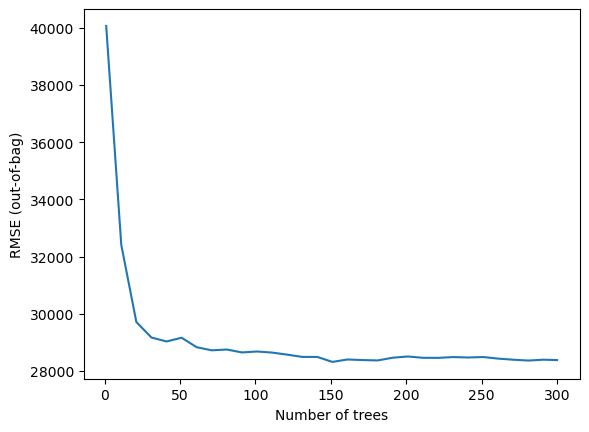

In [143]:
import matplotlib.pyplot as plt
logs = rf.make_inspector().training_logs()
plt.plot([log.num_trees for log in logs], [log.evaluation.rmse for log in logs])
plt.xlabel("Number of trees")
plt.ylabel("RMSE (out-of-bag)")
plt.show();

In [144]:
inspector = rf.make_inspector()
inspector.evaluation()

Evaluation(num_examples=1036, accuracy=None, loss=None, rmse=28377.277297988352, ndcg=None, aucs=None, auuc=None, qini=None)

In [145]:
evaluation = rf.evaluate(x=valid_ds, return_dict=True)

for name, value in evaluation.items():
    print(f"{name}: {value:.4f}")

1/1 [==============================] - 0s 186ms/step - loss: 0.0000e+00 - mse: 1094906880.0000
loss: 0.0000
mse: 1094906880.0000


## Variable importances

Variables importances generally indicate how much a feature contributes to the model predictions or quality. There are several ways to identify features using TensorFlow Decision Forests. Let us list the available Variable Importances for Decision Trees: 

In [147]:
print(f"Available variable importances:")
for importance in inspector.variable_importances().keys():
    print("\t", importance)

Available variable importances:
	 NUM_AS_ROOT
	 SUM_SCORE
	 INV_MEAN_MIN_DEPTH
	 NUM_NODES


As an example, let us display the important features for the Variable Importance NUM_AS_ROOT. 

The larger the importance score for NUM_AS_ROOT, the more impact it has on the outcome of the model. 

By default, the list is sorted from the most important to the least. From the output you can infer that the feature at the top of the list is used as the root node in most number of trees in the random forest than any other feature. 

In [149]:
inspector.variable_importances()["NUM_AS_ROOT"]

[("OverallQual" (1; #62), 119.0),
 ("ExterQual" (4; #22), 54.0),
 ("GarageCars" (1; #32), 35.0),
 ("Neighborhood" (4; #59), 34.0),
 ("YearBuilt" (1; #76), 17.0),
 ("GrLivArea" (1; #38), 15.0),
 ("TotalBsmtSF" (1; #73), 8.0),
 ("KitchenQual" (4; #44), 7.0),
 ("FullBath" (1; #29), 4.0),
 ("GarageArea" (1; #31), 3.0),
 ("BsmtQual" (4; #14), 2.0),
 ("GarageYrBlt" (1; #37), 2.0)]

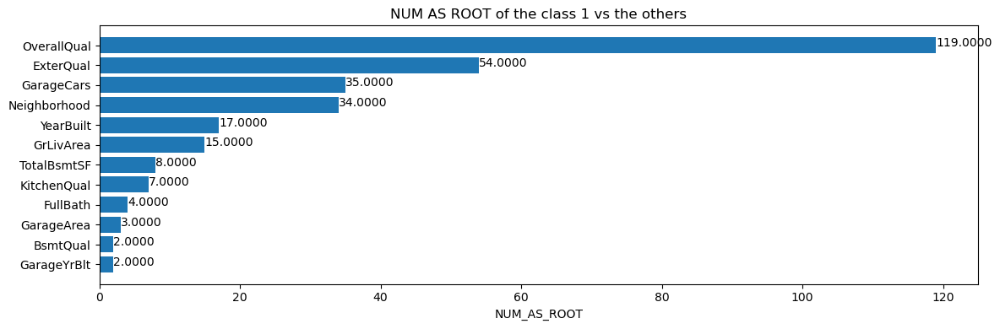

In [150]:
plt.figure(figsize=(12, 4))

# Mean decrease in AUC of the class 1 vs the others
variable_importance_metric = "NUM_AS_ROOT"
variable_importances = inspector.variable_importances()[variable_importance_metric]

# Extract the feature name and importance values

# 'variable_importances' is a list of <feature, importance> tuples
feature_names = [vi[0].name for vi in variable_importances]
feature_importances = [vi[1] for vi in variable_importances]
# The feature are ordered in decreasing importance value.
feature_ranks = range(len(feature_names))

bar = plt.barh(feature_ranks, feature_importances, label=[str(x) for x in feature_ranks])
plt.yticks(feature_ranks, feature_names)
plt.gca().invert_yaxis()

# TODO: replace with "plt.bar_label()" when available
# Label each bar with values
for importance, patch in zip(feature_importances, bar.patches):
    plt.text(patch.get_x() + patch.get_width(), patch.get_y(), f"{importance:.4f}", va="top")

plt.xlabel(variable_importance_metric)
plt.title("NUM AS ROOT of the class 1 vs the others")
plt.tight_layout()
plt.show();

## Submission

Finally predict on the competition test data using the model

In [194]:
test_file_path = "/Users/scottkeighley/Desktop/MSDS_422/house-prices-advanced-regression-techniques/test.csv"
test_data = pd.read_csv(test_file_path)
ids = test_data.pop('Id')

test_ds = tfdf.keras.pd_dataframe_to_tf_dataset(
    test_data,
    task = tfdf.keras.Task.REGRESSION)

preds = rf.predict(test_ds)
output = pd.DataFrame({'Id': ids,
                       'SalePrice': preds.squeeze()})

output.head()

2/2 [==============================] - 1s 43ms/step


,Id,SalePrice
0,1461,125189.117188
1,1462,155345.593750
2,1463,178985.375000
3,1464,181869.750000
4,1465,195234.515625


In [196]:
# 1) Read the Kaggle template
sample_submission_df = pd.read_csv(
    "/Users/scottkeighley/Desktop/MSDS_422/house-prices-advanced-regression-techniques/sample_submission.csv"
)

# 2) Get predictions (make sure test_ds has the same feature columns the model was trained on)
preds = rf.predict(test_ds, verbose=0).squeeze()   # -> shape (n,)

# 3) Fill and save
sample_submission_df["SalePrice"] = preds
sample_submission_df.to_csv("RandomForestModel.csv", index=False)
sample_submission_df.head()


,Id,SalePrice
0,1461,125189.117188
1,1462,155345.593750
2,1463,178985.375000
3,1464,181869.750000
4,1465,195234.515625


## Regularized Linear Model

For Cross-Validation

In [198]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib

import matplotlib.pyplot as plt
from scipy.stats import skew
from scipy.stats import pearsonr

%config InlineBackend.figure_format = 'retina' #set 'png' here when working on notebook
%matplotlib inline

In [200]:
train = pd.read_csv("/Users/scottkeighley/Desktop/MSDS_422/house-prices-advanced-regression-techniques/train.csv")
test = pd.read_csv("/Users/scottkeighley/Desktop/MSDS_422/house-prices-advanced-regression-techniques/test.csv")

In [202]:
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


#### Explanation

- This columns slice selects every column from MSSubClass through SaleCondition inclusive.
- This slice intentionally drops:
    - the left side: Id
    - the right side: the target SalePrice (exists only in train)
- Then you stack train and test features vertically into all_data
    - This is a common trick so you can apply the same preprocessing / encoding to both datasets at once

In [204]:
all_data = pd.concat((train.loc[:,'MSSubClass':'SaleCondition'],
                      test.loc[:,'MSSubClass':'SaleCondition']))

## Data Preprocessing

1. Transform the skewed numeric features by taking log(feature + 1) - this will make the features more normal
2. Create dummy variables for the categorical features
3. Replace the numeric missing values (NaN's) with the mean of their respective columns

#### Explanation of code below

- Sets a bigger default figure size and plots histograms of raw and log-transformed SalePrice
- Addresses Requirement #2 (EDA & visuals) and shows the log transform reduces right-skew - useful for linear models and RMSLE

array([[<Axes: title={'center': 'price'}>,
        <Axes: title={'center': 'log(price + 1)'}>]], dtype=object)

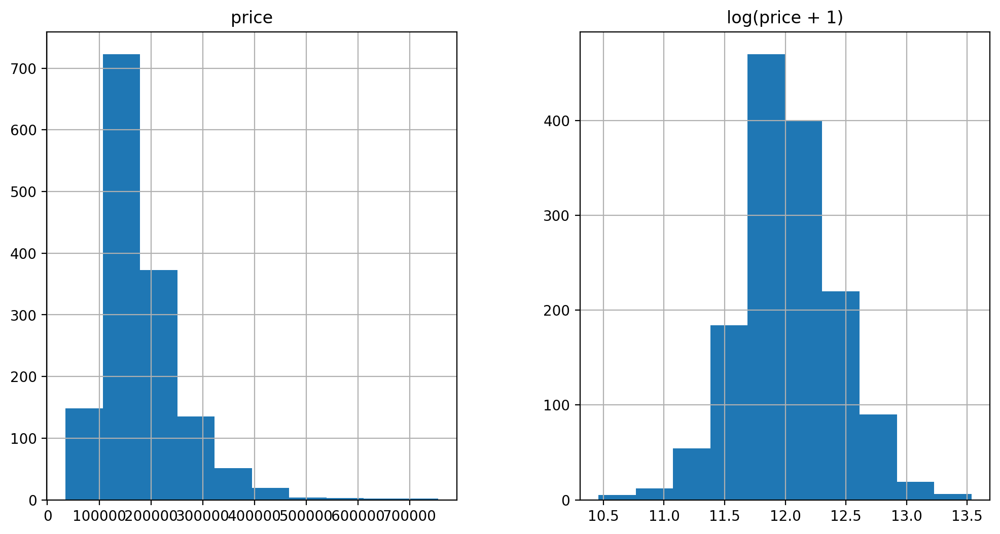

In [206]:
matplotlib.rcParams['figure.figsize'] = (12.0, 6.0)
prices = pd.DataFrame({"price":train["SalePrice"], "log(price + 1)":np.log1p(train["SalePrice"])})
prices.hist()

#### Explanation of code below

- Converts the target to log(SalePrice+1) in place
- Good for stabilizing variance and aligning with RMSLE
- Tip: keep the original for reporting / prediction
- Identifies numeric columns in your combined frame (all_data = train+test features). This list is the candidate for de-skewing
- Computes skew using training data only (good!) and selects features with skewnes > 0.75 (common Kaggle threshold)
- Sensible EDA-driven preprocessing (still part of Requirement #2)
- Applies log1p to the selected skewed features in both train and test so they are on the same scale
- Consistent transforms across splits

In [208]:
# log transform the target: 
train["SalePrice"] = np.log1p(train["SalePrice"])

# log transform skewed numeric features:
numeric_feats = all_data.dtypes[all_data.dtypes != "object"].index

skewed_feats = train[numeric_feats].apply(lambda x: skew(x.dropna())) # compute skewness
skewed_feats = skewed_feats[skewed_feats > 0.75]
skewed_feats = skewed_feats.index

all_data[skewed_feats] = np.log1p(all_data[skewed_feats])

#### Explanation of code below

- One-hot encodes all categories in the combined data, ensuring train / test get identical dummy columns
- Common Kaggle tactic

In [210]:
all_data = pd.get_dummies(all_data)

#### Explanation of code below

- Imputes missing values with the global mean computed on (train+test)
- Data leakage for cross-validation: imputing / statistics must be fit on training folds only, then applied to the validation fold and test. Computing means on all_data (which includes test) leaks information

In [212]:
# Filling NA's with the mean of the column
all_data = all_data.fillna(all_data.mean())

Note that above we use the all data to compute the mean value that is then used for imputation. This is a flawed approach since it introduces some minor data leakage. However, we decided to leave it here because it showcases some common mistakes we make

In [257]:
all_data.head()

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,4.110874,4.189655,9.042040,7,5,2003,2003,5.283204,6.561031,0.0,...,False,False,False,True,False,False,False,False,True,False
1,3.044522,4.394449,9.169623,6,8,1976,1976,0.000000,6.886532,0.0,...,False,False,False,True,False,False,False,False,True,False
2,4.110874,4.234107,9.328212,7,5,2001,2002,5.093750,6.188264,0.0,...,False,False,False,True,False,False,False,False,True,False
3,4.262680,4.110874,9.164401,7,5,1915,1970,0.000000,5.379897,0.0,...,False,False,False,True,True,False,False,False,False,False
4,4.110874,4.442651,9.565284,8,5,2000,2000,5.860786,6.486161,0.0,...,False,False,False,True,False,False,False,False,True,False


#### Explanation of code below

- Splits the processed matrix back to Train / Test by row count
- Uses y as the log-price (because we overwrote SalePrice above)
- Ready for modeling - but for regularized linear models, we'll also want feature scaling (Standard Scaler) done inside CV.

In [214]:
# Creating matrics for sklearn
X_train = all_data[:train.shape[0]]
X_test = all_data[train.shape[0]:]
y = train.SalePrice

## Models

Now we are going to use regularized linear regression models from the scikit learn module. We're going to try both l_1 (Lasso) and l_2 (Ridge) regularization. We'll also define a function that returns the cross-validation rmse error so we can evaluate our models and pick the best tuning par.

In [216]:
from sklearn.linear_model import Ridge, RidgeCV, ElasticNet, LassoCV, LassoLarsCV
from sklearn.model_selection import cross_val_score

def rmse_cv(model):
    rmse = np.sqrt(-cross_val_score(model, X_train, y, scoring="neg_mean_squared_error", cv = 5))
    return(rmse)

In [218]:
model_ridge = Ridge()

The main tuning parameter for the Ridge model is alpha - a regularization parameter that measures how flexible our model is. The higher the regularization the less prone our model will be to overfit. However it will also lose flexibility and might not capture all of the signal in the data

#### Explanation of code below

- We computed 5-fold CV RMSE for several Ridge penalties ($\alpha$)
- The U-shape is expected:
    - Too small $\alpha$ - weak regularization - variance / overfit up - error up
    - Too large $\alpha$ - too much shrinkage - bias up - error up
    - Your minimum ($\alpha$ ~ 8-12 from the plot) is the sweet spot
- Satisfies Req #1 (cross-validation design) and helps pick a hyperparameter
- Note: because our target y is log(SalePrice), this RMSE is in log units (numerically the RMSLE). If you want dollar error, back-transform predictions to $ and compute RMSE on the original scale

In [220]:
alphas = [0.05, 0.1, 0.3, 1, 3, 5, 10, 15, 30, 50, 75]
cv_ridge = [rmse_cv(Ridge(alpha = alpha)).mean()
            for alpha in alphas]

<Axes: title={'center': 'Validation'}>

Text(0.5, 0, 'alpha')

Text(0, 0.5, 'rmse')

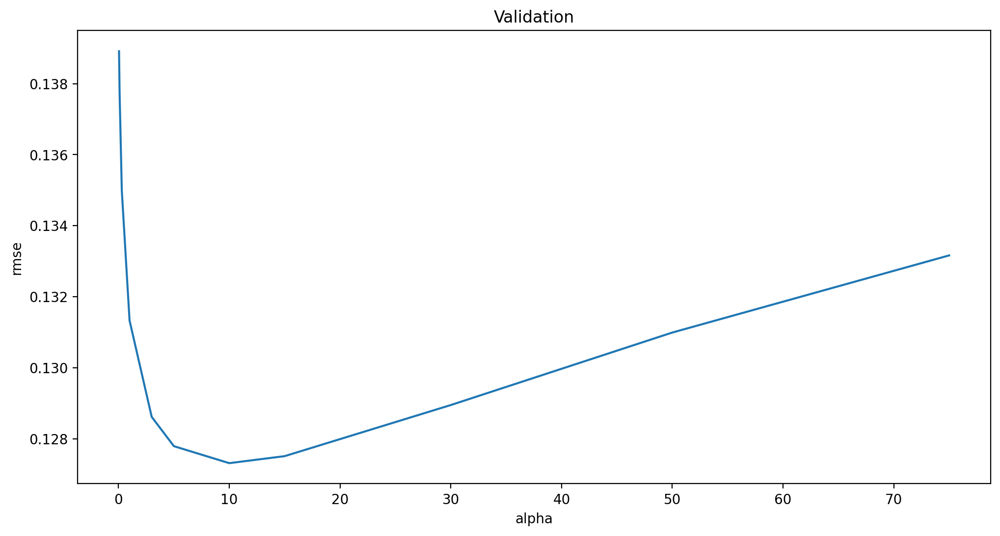

In [222]:
cv_ridge = pd.Series(cv_ridge, index = alphas)
cv_ridge.plot(title = "Validation")
plt.xlabel("alpha")
plt.ylabel("rmse")

Note the U-shaped curve. When alpha is too large the regularization is too strong and the model cannot capture all the complexities in the data. If however we let the model be too flexible (alpha too small) the model begins to overfit. A value of alpha = 10 is about right based on the plot above.

In [224]:
cv_ridge.min()

0.12731233261727548

For the Ridge regression we get a rmsle of about 0.127. Let's try out the Lasso model. We will do a slightly different approach here and use the built-in Lasso CV to figure out the best alpha for us. For some reason the alphas in Lasso CV are really the inverse or the alphas in Ridge

#### Explanation of code below

- L1 (LASSO) zeroes many coefficients - built-in feature selection
- Our bar chart shows top +/- effects (on log price). Typical positives: GrLivArea, quality dummies, premium neighborhoods; negatives: rare roof materials, adverse conditions, certain zoning dummies, etc.
- Delivers Req #3 (second model) and is a nice seque to Req #4 (indicator terms) since many one-hots are exactly that
- Caution: LASSO is scale-sensitive. Because our features are a mix of log-transformed numerics (still varying in scale) and one-hots (0/1), it's best to standardize numerics inside a pipline before LASSO so the penalty treats features comparably

In [226]:
model_lasso = LassoCV(alphas = [1, 0.1, 0.001, 0.0005]).fit(X_train, y)

In [228]:
rmse_cv(model_lasso).mean()

0.12256747906999563

The lasso performs even better so we'll just this one to predict on the next test set. Another thing about the Lasso is that it does feature selection for you - setting coefficients of features it deems unimportant to zero. Let's take a look at the coefficients

In [230]:
coef = pd.Series(model_lasso.coef_, index = X_train.columns)

In [232]:
print("Lasso picked " + str(sum(coef != 0)) + " variables and eliminated the other " + str(sum(coef ==0)) + " variables")

Lasso picked 110 variables and eliminated the other 177 variables


One thing to note here however is that the features selected are not necessarily the "correct" ones - especially since there are a lot of collinear features in this dataset. One idea to try here is to run Lasso a few times on bootstrapped samples and see how stable the feature selection is.

In [234]:
imp_coef = pd.concat([coef.sort_values().head(10),
                      coef.sort_values().tail(10)])

<Axes: >

Text(0.5, 1.0, 'Coefficients in the Lasso Model')

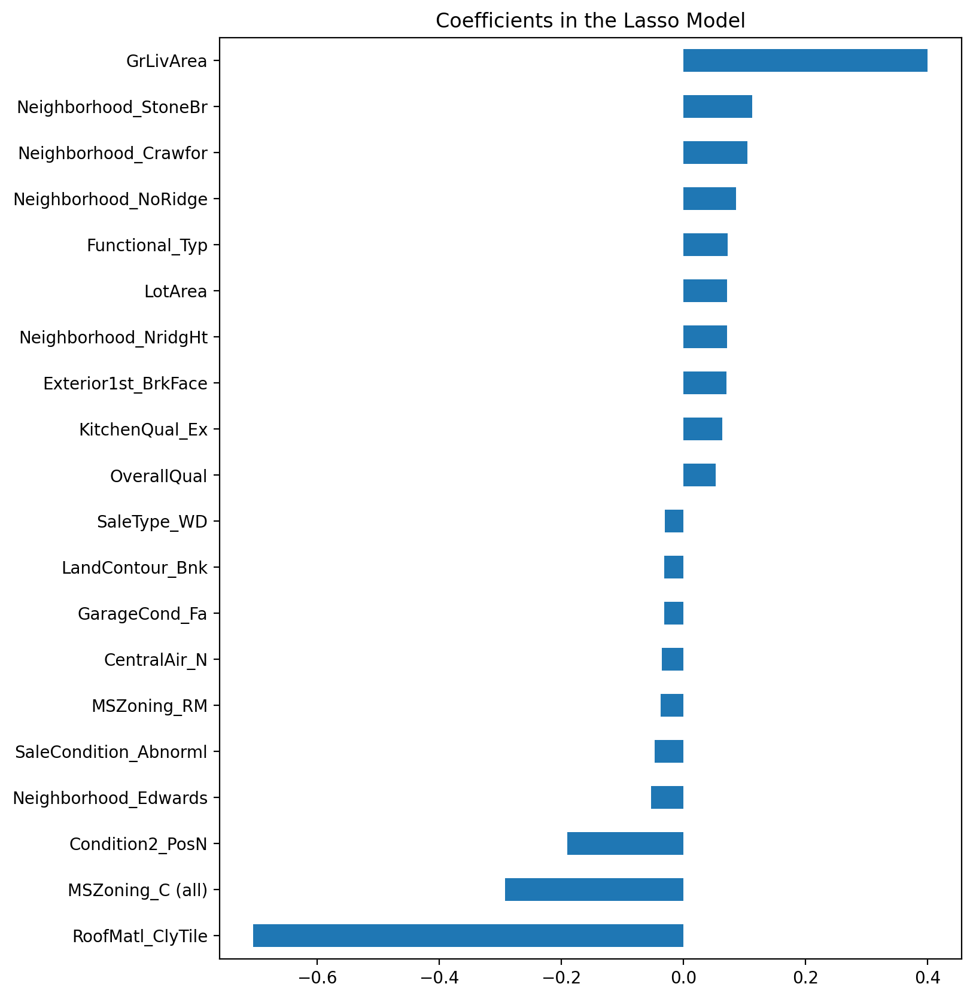

In [236]:
matplotlib.rcParams['figure.figsize'] = (8.0, 10.0)
imp_coef.plot(kind = "barh")
plt.title("Coefficients in the Lasso Model")

The most important positive feature is GrLivArea - the above ground area by square feet. This definitely makes sense. Then a few other location and quality features contribute positively. Some of the negative features make less sense and would be worth looking into more - it seems like they might come from unbalanced categorical variables.

Also note that unlike the feature importance you'd get from a random forest these are actual coefficients in your model - so you can say precisely why the predicted price is what it is. The only issue here is that we log_transformed both the target and the numeric features so the actual magnitudes are a bit hard to interpret and also the relationship is now multiplicative and not additive.

#### Explanation of code below

- The cloud is roughly centered at 0 (good), but you can see wider spread at higher-fitted values - mild heteroscedasicity (common for housing)
- Contributes to Req #6 (evaluate assumptions). Add a Q-Q plot for normality and residuals vs. key predictors to strengthen this section

<Axes: xlabel='preds', ylabel='residuals'>

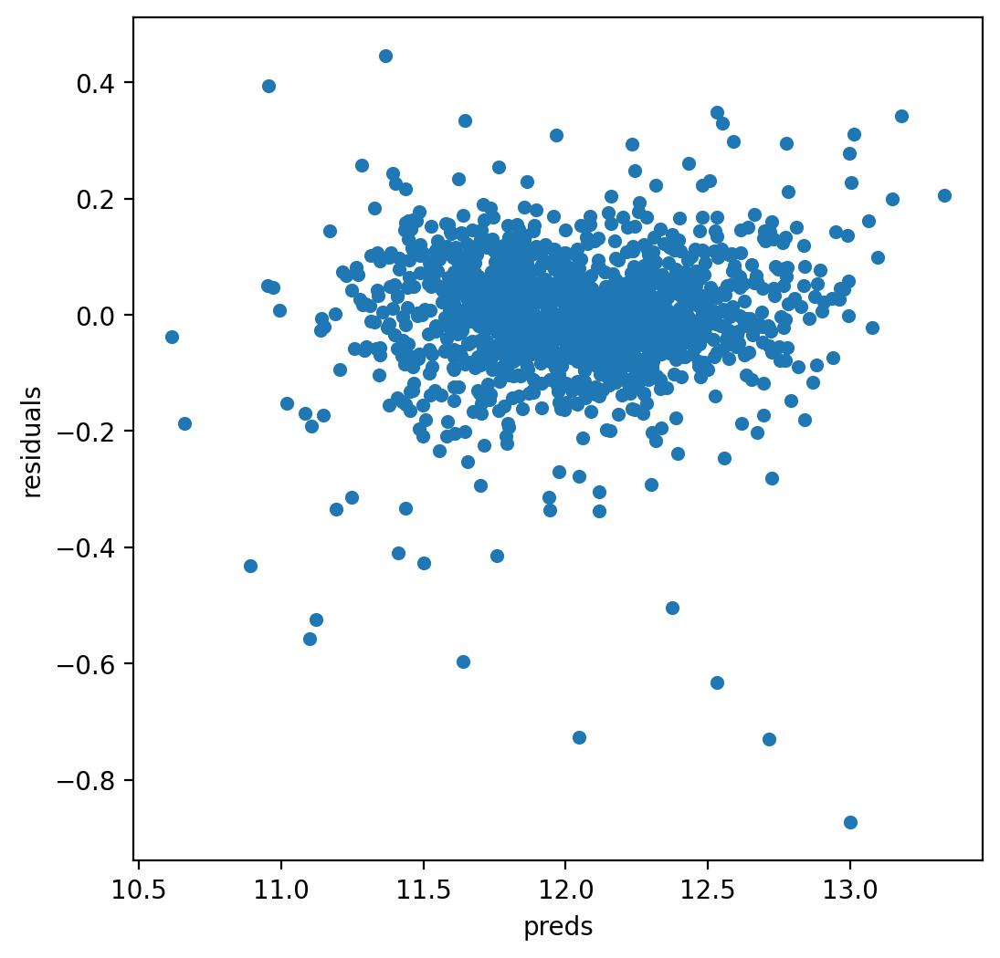

In [238]:
# Look at the residuals as well
matplotlib.rcParams['figure.figsize'] = (6.0, 6.0)

preds = pd.DataFrame({"preds":model_lasso.predict(X_train), "true":y})
preds["residuals"] = preds["true"] - preds["preds"]
preds.plot(x = "preds", y = "residuals",kind = "scatter")

## Adding an xgboost model:

In [163]:
#%pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 1.9 MB/s eta 0:00:0000:0100:01
Note: you may need to restart the kernel to use updated packages.


In [240]:
import xgboost as xgb

#### Explanation of code below

- Wraps matrices in XGBoost's fast DMatrix
- Note: your y is log(SalePrice) from earlier, so the model learns in log space (good for RMSLE-style performance)
- Runs k-fold CV inside XGBoost (with default objective reg:squarederror)
- The plot shows train RMSE steadily decreasing (orange) while test RMSE (blue) drops then plateaus: classic overfitting gap after ~300-400 trees
- Early stopping would pick the round where test-rmse-mean is minimal; using that round (or something close) is best
- Train vs. Test RMSE curve
    - Train (orange) keeps dropping - the model fits training nose as trees increase
    - Test (blue) drops then plateaus around ~300-400 trees - diminishing returns; going far past the minimum hurts generalization
    - The gap is healthy - not huge - thanks to shallow trees (max_depth=2) and moderate learning rate

In [242]:
dtrain = xgb.DMatrix(X_train, label = y)
dtest = xgb.DMatrix(X_test)

params = {"max_depth":2, "eta":0.1}
model = xgb.cv(params, dtrain, num_boost_round=500, early_stopping_rounds=100)

<Axes: >

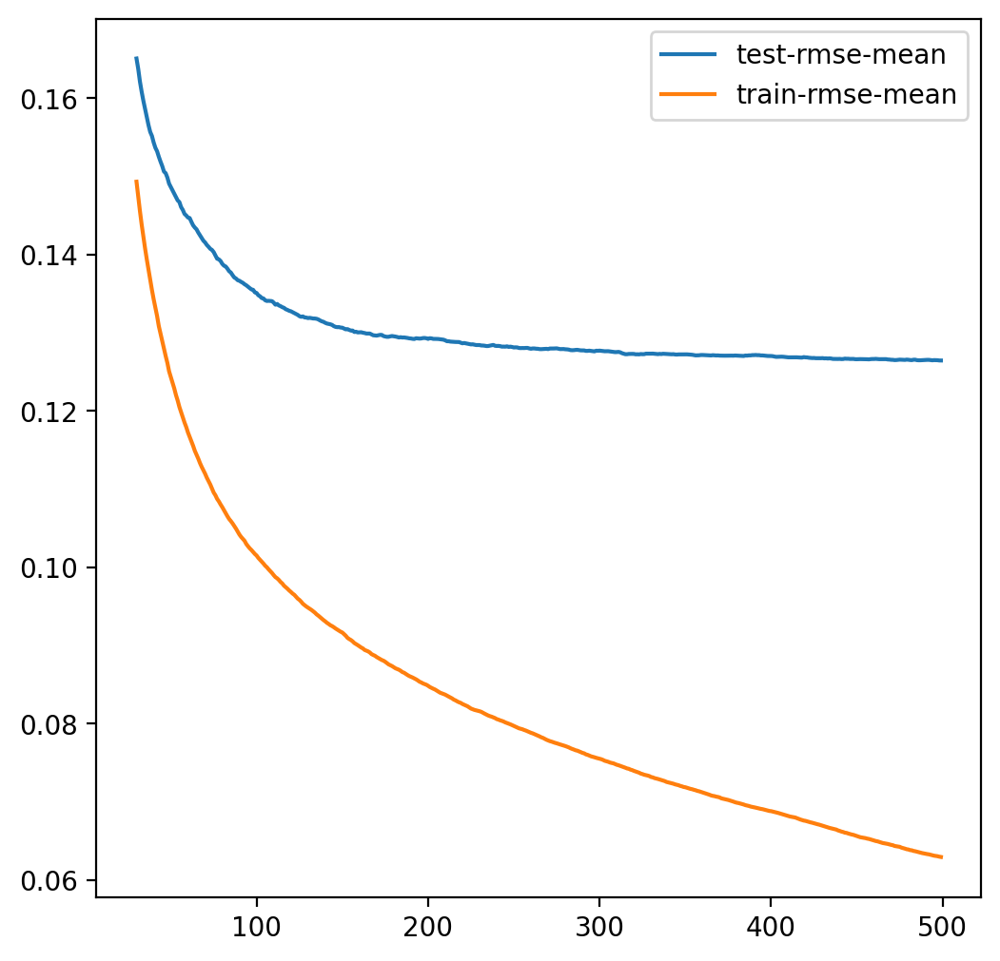

In [244]:
model.loc[30:,["test-rmse-mean", "train-rmse-mean"]].plot()

#### Explanation of code below

- Trains a final XGB on all training rows using a fixed n_estimators (chosen from the CV curve)
- You can also set n_estimators=best_round from xgb.cv for consistency

In [246]:
model_xgb = xgb.XGBRegressor(n_estimators=360, max_depth=2, learning_rate=0.1) #the params were tuned using xgb.cv
model_xgb.fit(X_train, y)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=2,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=360,
             n_jobs=None, num_parallel_tree=None, ...)

#### Explanation of code below

- Both models were trained on log(SalePrice); we correctly invert transform for the Kaggle submission

In [248]:
xgb_preds = np.expm1(model_xgb.predict(X_test))
lasso_preds = np.expm1(model_lasso.predict(X_test))

#### Explanation of code below

- Shows model agreement. Tight diagonal = both models predict similarly; the few off-diagonal points are where the models disagree (potential leverage for ensembling)
- LASSO vs. XGB prediction scatter
    - Points hugging the diagonal - the models largely agree (both capture size / quality / location)
    - Outliers above / below the diagonal - cases where one model sees a pattern the other misses (e.g., nonlinear interactions XGB captures, or linear signal LASSO generalizes better). Those cases are exactly why blending can help

<Axes: xlabel='xgb', ylabel='lasso'>

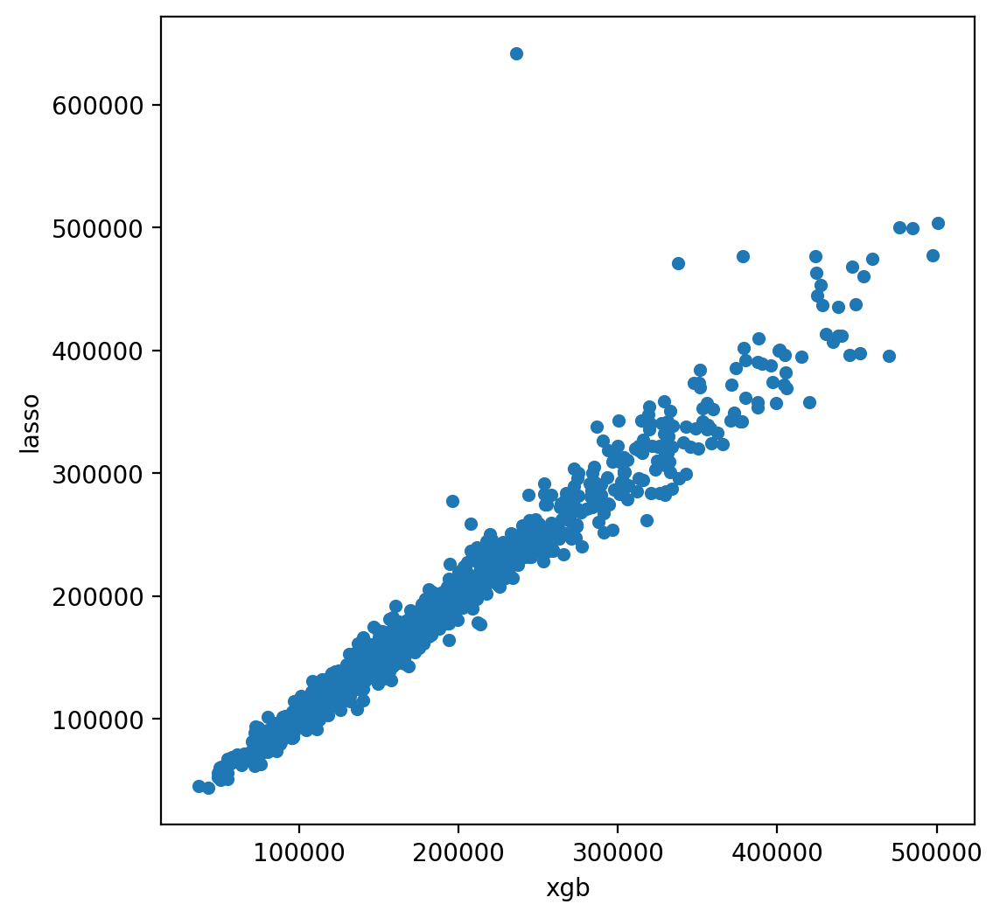

In [250]:
predictions = pd.DataFrame({"xgb":xgb_preds, "lasso":lasso_preds})
predictions.plot(x = "xgb", y = "lasso", kind = "scatter")

#### Explanation of code below

- Simple weighted average (blend): 70% LASSO + 30% XGB. Blending often reduces variance and improves leaderboard score
- Minor nits: the filename says "ridge" though it's a LASSO / XGB blend - rename to avoid confustion

In [252]:
preds = 0.7*lasso_preds + 0.3*xgb_preds

In [254]:
solution = pd.DataFrame({"id":test.Id, "SalePrice":preds})
solution.to_csv("lasso_xgb.csv", index = False)

## ElasticNet

## Imports

In [2]:
# pandas for data loading, manipulation etc.
import pandas as pd

# numeric functions
import numpy as np
from scipy import stats
from math import ceil

# plotting
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# modelling
from sklearn.model_selection import GridSearchCV, RepeatedKFold, cross_val_score
from sklearn.metrics import make_scorer
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet
from sklearn.svm import LinearSVR, SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.preprocessing import PolynomialFeatures

## Load Data

Load the train and test data into pandas dataframes. Combine them into a single dataframe so that it's easy to apply any feature transformations we use to both sets at the same time

In [4]:
# Load the data
df_train = pd.read_csv('/Users/scottkeighley/Desktop/MSDS_422/house-prices-advanced-regression-techniques/train.csv',index_col='Id')
df_test = pd.read_csv('/Users/scottkeighley/Desktop/MSDS_422/house-prices-advanced-regression-techniques/test.csv',index_col='Id')

# ids of full training dataset
id_train = df_train.index

# ids of full test dataset
id_test = df_test.index

# combine train and test datas into one dataframe
df_all = pd.concat([df_train,df_test], sort=True)
df_all.head(5)

,1stFlrSF,2ndFlrSF,3SsnPorch,Alley,BedroomAbvGr,BldgType,BsmtCond,BsmtExposure,BsmtFinSF1,BsmtFinSF2,...,SaleType,ScreenPorch,Street,TotRmsAbvGrd,TotalBsmtSF,Utilities,WoodDeckSF,YearBuilt,YearRemodAdd,YrSold
Id,,,,,,,,,,,,,,,,,,,,,
1,856,854,0,NaN,3,1Fam,TA,No,706.0,0.0,...,WD,0,Pave,8,856.0,AllPub,0,2003,2003,2008
2,1262,0,0,NaN,3,1Fam,TA,Gd,978.0,0.0,...,WD,0,Pave,6,1262.0,AllPub,298,1976,1976,2007
3,920,866,0,NaN,3,1Fam,TA,Mn,486.0,0.0,...,WD,0,Pave,6,920.0,AllPub,0,2001,2002,2008
4,961,756,0,NaN,3,1Fam,Gd,No,216.0,0.0,...,WD,0,Pave,7,756.0,AllPub,0,1915,1970,2006
5,1145,1053,0,NaN,4,1Fam,TA,Av,655.0,0.0,...,WD,0,Pave,9,1145.0,AllPub,192,2000,2000,2008


## Columns with NaN Values

First thing to notice is that the data contains a lot of NaN values, which need to be dealt with

In [6]:
# summary of columns with NaN values

cols_with_na = df_all.isnull().sum()
cols_with_na = cols_with_na[cols_with_na>0]
print(cols_with_na.sort_values(ascending=False))

PoolQC          2909
MiscFeature     2814
Alley           2721
Fence           2348
MasVnrType      1766
SalePrice       1459
FireplaceQu     1420
LotFrontage      486
GarageQual       159
GarageYrBlt      159
GarageCond       159
GarageFinish     159
GarageType       157
BsmtCond          82
BsmtExposure      82
BsmtQual          81
BsmtFinType2      80
BsmtFinType1      79
MasVnrArea        23
MSZoning           4
Utilities          2
Functional         2
BsmtHalfBath       2
BsmtFullBath       2
GarageCars         1
Exterior2nd        1
KitchenQual        1
Exterior1st        1
Electrical         1
BsmtUnfSF          1
BsmtFinSF2         1
BsmtFinSF1         1
SaleType           1
TotalBsmtSF        1
GarageArea         1
dtype: int64


## Meaningful NaN Values

Looking at the data description file, it can be seen that a lot of the NaNs are not true missing values, but rather indicate that the property does not have that feature (e.g. a property with NaN garage type has no garage)

We want to preserve this information, so I replace the NaNs with the string "None" in the categorical features, or with zero for the numeric features, where this applies

In [8]:
# columns where NaN values have meaning e.g. no pool etc.
cols_fillna = ['PoolQC','MiscFeature','Alley','Fence','MasVnrType','FireplaceQu',
               'GarageQual','GarageCond','GarageFinish','GarageType',
               'BsmtExposure','BsmtCond','BsmtQual','BsmtFinType1','BsmtFinType2']

# replace 'NaN' with 'None' in these columns
for col in cols_fillna:
    df_all[col].fillna('None',inplace=True)
    
#GarageYrBlt nans: no garage. Fill with property YearBuilt.
#(more appropriate than 0, which would be ~2000 away from all other values)
df_all.loc[df_all.GarageYrBlt.isnull(),'GarageYrBlt'] = df_all.loc[df_all.GarageYrBlt.isnull(),'YearBuilt']

#No masonry veneer - fill area with 0
df_all.MasVnrArea.fillna(0,inplace=True)

#No basement - fill areas/counts with 0    
df_all.BsmtFullBath.fillna(0,inplace=True)
df_all.BsmtHalfBath.fillna(0,inplace=True)
df_all.BsmtFinSF1.fillna(0,inplace=True)
df_all.BsmtFinSF2.fillna(0,inplace=True)
df_all.BsmtUnfSF.fillna(0,inplace=True)
df_all.TotalBsmtSF.fillna(0,inplace=True)

#No garage - fill areas/counts with 0
df_all.GarageArea.fillna(0,inplace=True)
df_all.GarageCars.fillna(0,inplace=True)

df_all[cols_fillna].head(5)

/var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/ipykernel_73466/4010564198.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_all[col].fillna('None',inplace=True)
/var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/ipykernel_73466/4010564198.py:15: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behav

,PoolQC,MiscFeature,Alley,Fence,MasVnrType,FireplaceQu,GarageQual,GarageCond,GarageFinish,GarageType,BsmtExposure,BsmtCond,BsmtQual,BsmtFinType1,BsmtFinType2
Id,,,,,,,,,,,,,,,
1,None,None,None,None,BrkFace,None,TA,TA,RFn,Attchd,No,TA,Gd,GLQ,Unf
2,None,None,None,None,None,TA,TA,TA,RFn,Attchd,Gd,TA,Gd,ALQ,Unf
3,None,None,None,None,BrkFace,TA,TA,TA,RFn,Attchd,Mn,TA,Gd,GLQ,Unf
4,None,None,None,None,None,Gd,TA,TA,Unf,Detchd,No,Gd,TA,ALQ,Unf
5,None,None,None,None,BrkFace,TA,TA,TA,RFn,Attchd,Av,TA,Gd,GLQ,Unf


## LotFrontage NaN Values

The most difficult NaNs to deal with are those in the LotFrontage column. The simplest thing to do would be to replace the NaNs with the mean or median LotFrontage. For a bit of extra practice with sklearn, and to hopefully give a more accurage estimate, we decided to fit a Ridge model (linear regression with regularisation) to predict the missing values. We don't include the SalePrice in the model, to avoid leakage between the train and test datasets. 

The model isn't perfect, but hopefully better than just using the mean. Features relating the size and shape of the lot appear amongst the largest coefficients, which makes sense, and the predicted values look sensible.

In [10]:
# Function to normalize a column of values to lie between 0 and 1
def scale_minmax(col):
    return (col-col.min())/(col.max()-col.min())

----------------
Intercept: 93.20848325398711
----------------
LotArea             71.475879
RoofMatl_ClyTile    49.396968
1stFlrSF            27.547832
PoolArea            26.905146
RoofStyle_Shed      25.874524
GrLivArea           22.148975
Foundation_Wood     20.075497
LotShape_IR3        17.721471
GarageArea          17.536239
BldgType_2fmCon     16.123235
dtype: float64
----------------
Utilities_AllPub      -11.610027
BldgType_TwnhsE       -12.070870
BsmtCond_Po           -12.151678
Exterior1st_CemntBd   -14.553347
PoolQC_Fa             -14.706527
RoofMatl_WdShake      -15.579127
BldgType_Twnhs        -17.924473
RoofMatl_WdShngl      -18.222015
GarageYrBlt           -21.591319
LotConfig_CulDSac     -23.428742
dtype: float64
----------------
R2: 0.6889229361774905
----------------


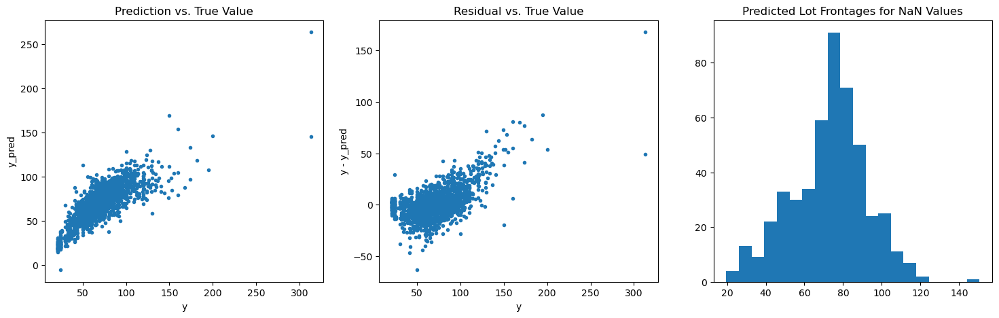

In [11]:
#LotFrontage
# fill nan values using a linear regressor

# convert categoricals to dummies, exclude SalePrice from model
#df_frontage = pd.get_dummies(df_all.drop('SalePrice',axis=1))
df_frontage = pd.get_dummies(df_all.drop('SalePrice', axis=1), dtype=float)

import numpy as np
from pandas.api.types import is_numeric_dtype

def scale_minmax(col):
    if not is_numeric_dtype(col):
        return col
    col = col.astype(float)
    mn, mx = col.min(), col.max()
    denom = mx - mn
    if pd.isna(denom) or denom == 0:
        return col*0.0  # all zeros for constant columns
    return (col - mn) / denom

# normalise columns to 0-1
for col in df_frontage.drop('LotFrontage',axis=1).columns:
    df_frontage[col] = scale_minmax(df_frontage[col])

lf_train = df_frontage.dropna()
lf_train_y = lf_train.LotFrontage
lf_train_X = lf_train.drop('LotFrontage',axis=1)  

# fit model
lr = Ridge()
lr.fit(lf_train_X, lf_train_y)

# check model results
lr_coefs = pd.Series(lr.coef_,index=lf_train_X.columns)

print('----------------')
print('Intercept:',lr.intercept_)
print('----------------')
print(lr_coefs.sort_values(ascending=False).head(10))
print('----------------')
print(lr_coefs.sort_values(ascending=False).tail(10))
print('----------------')
print('R2:',lr.score(lf_train_X,lf_train_y))
print('----------------')

lf_pred_y = lr.predict(lf_train_X)
plt.figure(figsize=(18,5))
plt.subplot(1,3,1)
plt.plot(lf_train_y,lf_pred_y,'.')
plt.xlabel('y')
plt.ylabel('y_pred');
plt.title('Prediction vs. True Value')

plt.subplot(1,3,2)
plt.plot(lf_train_y, lf_train_y-lf_pred_y,'.')
plt.xlabel('y')
plt.ylabel('y - y_pred');
plt.title('Residual vs. True Value')


# fill na values using model predictions
nan_frontage = df_all.LotFrontage.isnull()
X = df_frontage[nan_frontage].drop('LotFrontage',axis=1)
y = lr.predict(X)

plt.subplot(1,3,3)
plt.hist(y,bins=20)
plt.title('Predicted Lot Frontages for NaN Values')

# fill nan values
df_all.loc[nan_frontage,'LotFrontage'] = y

## Remaining NaNs

Now we're just left with a handful of remaining features / properties that have NaN values. All of them happen to be categorical variables, and we just replace the missing values with the mode for that feature. Most of the remaining NaNs are in the test dataset, otherwise we may have just deleted them.

In [13]:
# Remaining NaN values
cols_with_na = df_all.drop('SalePrice',axis=1).isnull().sum()
cols_with_na = cols_with_na[cols_with_na>0]

print(cols_with_na.sort_values(ascending=False))

rows_with_na = df_all.drop('SalePrice',axis=1).isnull().sum(axis=1)
rows_with_na = rows_with_na[rows_with_na>0]
print(rows_with_na.sort_values(ascending=False))

# Fill remaining NaNs with mode in that column
for col in cols_with_na.index:
    df_all[col].fillna(df_all[col].mode()[0], inplace=True)

MSZoning       4
Functional     2
Utilities      2
Electrical     1
Exterior1st    1
Exterior2nd    1
KitchenQual    1
SaleType       1
dtype: int64
Id
1916    2
2152    2
2217    2
1380    1
1556    1
1946    1
2251    1
2474    1
2490    1
2905    1
dtype: int64


/var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/ipykernel_73466/1195868892.py:13: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_all[col].fillna(df_all[col].mode()[0], inplace=True)


In [14]:
# Now no more NaN values apart from SalePrice in test data
df_all.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2919 entries, 1 to 2919
Data columns (total 80 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   1stFlrSF       2919 non-null   int64  
 1   2ndFlrSF       2919 non-null   int64  
 2   3SsnPorch      2919 non-null   int64  
 3   Alley          2919 non-null   object 
 4   BedroomAbvGr   2919 non-null   int64  
 5   BldgType       2919 non-null   object 
 6   BsmtCond       2919 non-null   object 
 7   BsmtExposure   2919 non-null   object 
 8   BsmtFinSF1     2919 non-null   float64
 9   BsmtFinSF2     2919 non-null   float64
 10  BsmtFinType1   2919 non-null   object 
 11  BsmtFinType2   2919 non-null   object 
 12  BsmtFullBath   2919 non-null   float64
 13  BsmtHalfBath   2919 non-null   float64
 14  BsmtQual       2919 non-null   object 
 15  BsmtUnfSF      2919 non-null   float64
 16  CentralAir     2919 non-null   object 
 17  Condition1     2919 non-null   object 
 18  Condition2   

## Basement Finish Types

With all the NaN values dealt with, it's time to start investigating and playing with the data to get it in the format we want for model fitting. Note that the final order things appear in the notebook is not the order we did them first - a lot of time was spent exploring the data (looking at e.g., the scatter and distribution plots shown later) before we decided on how to fill the NaNs (above), and the feature manipulations below.

In the basement features there are two areas representing a certain finish type, e.g., an area that is converted to "Good living quarters", and an area that is unfinished. The finish type and areas are in spearate columns, and a simple model wouldn't catch the interaction between the type and area. So we create new columns representing the area of each finish type the property's basement has, and remove the original columns. 

We also realized the area by itself may not be the most useful stat - large properties will have large areas and high sale prices 'by default'. What might be more interesting is the fraction of the basement that is of each type. We create more new columsn for these fractions.

In the plots below there is a slight positive correlation between the unfinished area and sale price (as larger properties are more likely to have large unfinished areas), but a slight negative correlation between the unfinished fraction and the sale price, as having the basement finished is undesirable. 

,BsmtCond,BsmtExposure,BsmtFullBath,BsmtHalfBath,BsmtQual,BsmtUnfSF,TotalBsmtSF,BsmtGLQSF,BsmtALQSF,BsmtBLQSF,BsmtRecSF,BsmtLwQSF,BsmtGLQFrac,BsmtALQFrac,BsmtBLQFrac,BsmtRecFrac,BsmtLwQFrac,BsmtUnfFrac
Id,,,,,,,,,,,,,,,,,,
1,TA,No,1.0,0.0,Gd,150.0,856.0,706,0,0,0,0,0.824766,0.000000,0.0,0.0,0.0,0.175234
2,TA,Gd,0.0,1.0,Gd,284.0,1262.0,0,978,0,0,0,0.000000,0.774960,0.0,0.0,0.0,0.225040
3,TA,Mn,1.0,0.0,Gd,434.0,920.0,486,0,0,0,0,0.528261,0.000000,0.0,0.0,0.0,0.471739
4,Gd,No,1.0,0.0,TA,540.0,756.0,0,216,0,0,0,0.000000,0.285714,0.0,0.0,0.0,0.714286
5,TA,Av,1.0,0.0,Gd,490.0,1145.0,655,0,0,0,0,0.572052,0.000000,0.0,0.0,0.0,0.427948


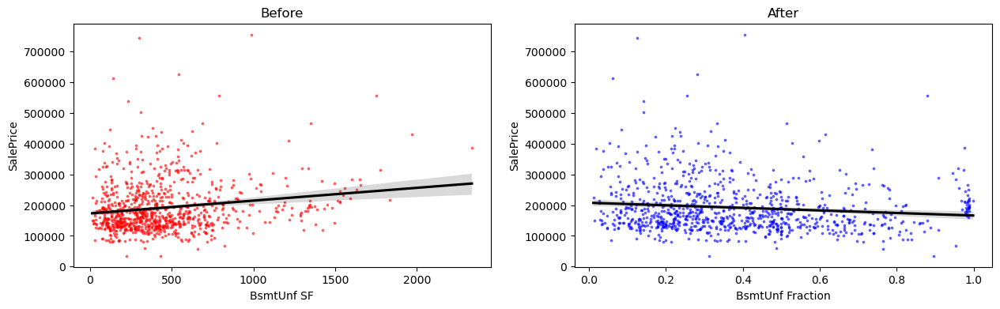

In [16]:
# create separate columns for area of each possible
# basement finish type
bsmt_fin_cols = ['BsmtGLQ','BsmtALQ','BsmtBLQ',
                 'BsmtRec','BsmtLwQ']

for col in bsmt_fin_cols:
    # initialise as columns of zeros
    df_all[col+'SF'] = 0

# fill remaining finish type columns
for row in df_all.index:
    fin1 = df_all.loc[row,'BsmtFinType1']
    if (fin1!='None') and (fin1!='Unf'):
        # add area (SF) to appropriate column
        df_all.loc[row,'Bsmt'+fin1+'SF'] += df_all.loc[row,'BsmtFinSF1']
        
    fin2 = df_all.loc[row,'BsmtFinType2']
    if (fin2!='None') and (fin2!='Unf'):
        df_all.loc[row,'Bsmt'+fin2+'SF'] += df_all.loc[row,'BsmtFinSF2']


# remove initial BsmtFin columns
df_all.drop(['BsmtFinType1','BsmtFinSF1','BsmtFinType2','BsmtFinSF2'], axis=1, inplace=True)

# already have BsmtUnf column in dataset
bsmt_fin_cols.append('BsmtUnf')

# also create features representing the fraction of the basement that is each finish type
for col in bsmt_fin_cols:  # e.g., ['BsmtGLQ','BsmtALQ','BsmtBLQ','BsmtRec','BsmtLwQ','BsmtUnf']
    num = df_all[f'{col}SF'].astype(float)
    den = df_all['TotalBsmtSF'].astype(float)
    df_all[f'{col}Frac'] = np.divide(
        num, den,
        out=np.zeros_like(den, dtype=float),
        where=den.to_numpy() != 0
    )

#plot to demonstrate the effect of the new feature
mask = (
    (df_all['BsmtUnfFrac'] > 0) &
    (df_all['BsmtUnfFrac'] < 1) &
    (df_all['SalePrice'].notna())  # important if df_all mixes train+test
)
d = df_all.loc[mask]

plt.figure(figsize=(15,4))

plt.subplot(1,2,1)
sns.regplot(
    data=d, x='BsmtUnfSF', y='SalePrice',
    scatter_kws={'marker':'.','s':3,'alpha':0.5,'color':'r'},
    line_kws={'color':'k'}
)
plt.xlabel('BsmtUnf SF')
plt.title('Before')

plt.subplot(1,2,2)
sns.regplot(
    data=d, x='BsmtUnfFrac', y='SalePrice',
    scatter_kws={'marker':'.','s':3,'alpha':0.5,'color':'b'},
    line_kws={'color':'k'}
)
plt.xlabel('BsmtUnf Fraction')
plt.title('After')


df_all.loc[:,df_all.columns.str.contains('Bsmt')].head(5)

## 1st and 2nd Floor Area

Like the basement, we thought the fraction of each property's area that is on the 1st floor, 2nd floot, or unfinished may be useful so we create columns for these. 

We also create columns to indicate the total size of the property - TotalAreaSF for the total size of all interior areas, LivingAreaSF for the total area of living quarters (including any in the basement), and StorageAreaSF for total are of non-living quarter interiors (garage etc.)

In [18]:
df_all['LowQualFinFrac'] = df_all['LowQualFinSF']/df_all['GrLivArea']
df_all['1stFlrFrac'] = df_all['1stFlrSF']/df_all['GrLivArea']
df_all['2ndFlrFrac'] = df_all['2ndFlrSF']/df_all['GrLivArea']

df_all['TotalAreaSF'] = df_all['GrLivArea']+df_all['TotalBsmtSF']+df_all['GarageArea']+df_all['EnclosedPorch']+df_all['ScreenPorch']
df_all['LivingAreaSF'] = df_all['1stFlrSF'] + df_all['2ndFlrSF'] + df_all['BsmtGLQSF'] + df_all['BsmtALQSF'] + df_all['BsmtBLQSF']
df_all['StorageAreaSF'] = df_all['LowQualFinSF'] + df_all['BsmtRecSF'] + df_all['BsmtLwQSF'] + df_all['BsmtUnfSF'] + df_all['GarageArea']

## Categorical Features with Meaningful Ordering

Some of the categorical variables can directly be converted into numeric scales. For example, there are many 'quality' features, that have values ranging from "Excellent" to "Poor". These can be converted into integer scales, with the most desireable descriptions given the highest scores

In some cases we make an educated guess at what is most desireable (e.g., assume it is better to have a property that is not on a slope)

In [20]:
# Convert some categorical values to numeric scales

# Excellent, Good, Typical, Fair, Poor, None: Convert to 0-5 scale
cols_ExGd = ['ExterQual','ExterCond','BsmtQual','BsmtCond',
             'HeatingQC','KitchenQual','FireplaceQu','GarageQual',
            'GarageCond','PoolQC']

dict_ExGd = {'Ex':5,'Gd':4,'TA':3,'Fa':2,'Po':1,'None':0}

for col in cols_ExGd:
    df_all[col].replace(dict_ExGd, inplace=True)

display(df_all[cols_ExGd].head(5))

# Remaining columns
df_all['BsmtExposure'].replace({'Gd':4,'Av':3,'Mn':2,'No':1,'None':0}, inplace=True)

df_all['CentralAir'].replace({'Y':1,'N':0}, inplace=True)

df_all['Functional'].replace({'Typ':7,'Min1':6,'Min2':5,'Mod':4,'Maj1':3,'Maj2':2,'Sev':1,'Sal':0}, inplace=True)

df_all['GarageFinish'].replace({'Fin':3,'RFn':2,'Unf':1,'None':0}, inplace=True)

df_all['LotShape'].replace({'Reg':3,'IR1':2,'IR2':1,'IR3':0}, inplace=True)

df_all['Utilities'].replace({'AllPub':3,'NoSewr':2,'NoSeWa':1,'ELO':0}, inplace=True)

df_all['LandSlope'].replace({'Gt1':2,'Mod':1,'Sev':0}, inplace=True)

/var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/ipykernel_73466/900544764.py:11: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_all[col].replace(dict_ExGd, inplace=True)
/var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/ipykernel_73466/900544764.py:11: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
 

,ExterQual,ExterCond,BsmtQual,BsmtCond,HeatingQC,KitchenQual,FireplaceQu,GarageQual,GarageCond,PoolQC
Id,,,,,,,,,,
1,4,3,4,3,5,4,0,3,3,0
2,3,3,4,3,5,3,3,3,3,0
3,4,3,4,3,5,4,3,3,3,0
4,3,3,3,4,4,4,4,3,3,0
5,4,3,4,3,5,4,3,3,3,0


/var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/ipykernel_73466/900544764.py:16: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_all['BsmtExposure'].replace({'Gd':4,'Av':3,'Mn':2,'No':1,'None':0}, inplace=True)
/var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/ipykernel_73466/900544764.py:16: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option(

## Dealing with Zeroes

All those NaNs we replaced with zeroes earlier can actually be a bit of a nuisance. In a linear regression model, the large number of properties with, for example, no 2nd floor, and so zero 2nd floor area, will bias the estimated dependence between sale price and 2nd floor area.

To give the models flexibility to get around this issue, for features with a lot of zeros, we add a dummy variable to indicate whether that feature is present in the property or not. The effect of doing so is shown by the plot below. For a couple of features where very few properties have it, we remove the original feature and only keep the dummy variable. We also decided to count the "half bathroom" features literally as 0.5 bathrooms, added them to the "full bathroom" totals, then dropped the "half bathroom" columns.

In [22]:
# fraction of zeros in each column
frac_zeros = ((df_all==0).sum()/len(df_all))

# no. unique values in each column
n_unique = df_all.nunique()

# difference between frac. zeros and expected
# frac. zeros if values evenly distributed between
# classes
xs_zeros = frac_zeros - 1/n_unique

# create dataframe and display which columns may be problematic
zero_cols = pd.DataFrame({'frac_zeros':frac_zeros,'n_unique':n_unique,'xs_zeros':xs_zeros})
zero_cols = zero_cols[zero_cols.frac_zeros>0]
zero_cols.sort_values(by='xs_zeros',ascending=False,inplace=True)
display(zero_cols[(zero_cols.xs_zeros>0)])

#very few properties with Pool or 3SsnPorch
#replace columns with binary indicator
df_all['HasPool'] = (df_all['PoolQC']>0).astype(int)
df_all['Has3SsnPorch'] = (df_all['3SsnPorch']>0).astype(int)
df_all.drop(['PoolQC','PoolArea','3SsnPorch'],axis=1,inplace=True)

# 'half' bathrooms - add half value to 'full' bathrooms
df_all['BsmtFullBath'] = df_all['BsmtFullBath'] + 0.5*df_all['BsmtHalfBath']
df_all['FullBath'] = df_all['FullBath'] + 0.5*df_all['HalfBath']
df_all.drop(['BsmtHalfBath','HalfBath'],axis=1,inplace=True)

# create additional dummy variable for
# continuous variables with a lot of zeros
dummy_cols = ['LowQualFinSF','2ndFlrSF',
              'MiscVal','ScreenPorch','WoodDeckSF','OpenPorchSF',
              'EnclosedPorch','MasVnrArea','GarageArea','Fireplaces',             
              'BsmtGLQSF','BsmtALQSF','BsmtBLQSF','BsmtRecSF',
              'BsmtLwQSF','BsmtUnfSF','TotalBsmtSF']

for col in dummy_cols:
    df_all['Has'+col] = (df_all[col]>0).astype(int)

,frac_zeros,n_unique,xs_zeros
LowQualFinFrac,0.986297,39,0.960656
LowQualFinSF,0.986297,36,0.958519
3SsnPorch,0.987324,31,0.955066
MiscVal,0.964714,38,0.938398
PoolArea,0.995546,14,0.924118
BsmtLwQFrac,0.917437,225,0.912993
BsmtLwQSF,0.917437,199,0.912412
ScreenPorch,0.912299,121,0.904034
BsmtBLQFrac,0.885235,322,0.882129
BsmtBLQSF,0.885235,283,0.881701


/var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/ipykernel_73466/2702708637.py:38: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_all['Has'+col] = (df_all[col]>0).astype(int)
/var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/ipykernel_73466/2702708637.py:38: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_all['Has'+col] = (df_all[col]>0).astype(int)
/var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/ipykernel_73466/2702708637.py:38: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame

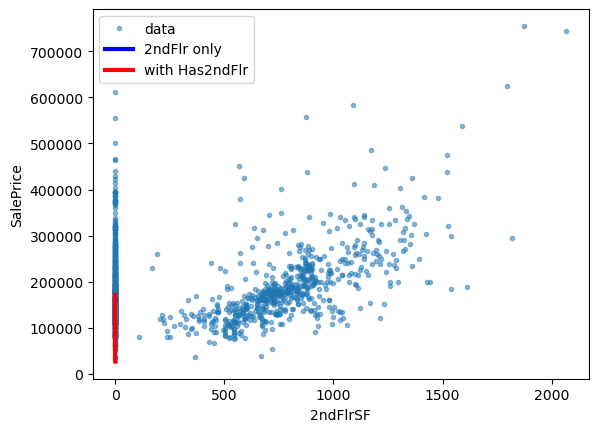

In [23]:
#PROBLEM OF LOTS OF ZEROS EXAMPLE -2ndFlrSF
#####
# mode only using 2ndflrsf
#####
tmp = scale_minmax(df_all[['SalePrice','2ndFlrSF','Has2ndFlrSF']].dropna())

y = tmp.SalePrice
X = tmp['2ndFlrSF']

plt.plot(X,y,'.',label='data',alpha=0.5)

lr = LinearRegression()
lr.fit(X.values.reshape(-1, 1),y)
lr_coefs = pd.Series(lr.coef_,index=['Has2ndFlrSF'])
lr_intercept = lr.intercept_

def regval(flr2ndSF):
    return flr2ndSF*lr_coefs + lr_intercept

plt.plot([0,1],[regval(0),regval(1)],'b',linewidth=3,label='2ndFlr only')

#####
# model using has2ndflr dummy variable
#####
tmp = scale_minmax(df_all[['SalePrice','2ndFlrSF','Has2ndFlrSF']].dropna())

y = tmp.SalePrice

X = tmp.drop('SalePrice',axis=1)

lr = LinearRegression()
lr.fit(X,y)
lr_coefs = pd.Series(lr.coef_,index=X.columns)
lr_intercept = lr.intercept_

def regval(flr2ndSF,has2nd):
    return flr2ndSF*lr_coefs['2ndFlrSF'] + has2nd*lr_coefs['Has2ndFlrSF'] + lr_intercept

plt.plot([0,0.02,1],[regval(0,0),regval(0.02,1),regval(1,1)],'r',linewidth=3,label='with Has2ndFlr')

plt.legend()
plt.xlabel('2ndFlrSF')
plt.ylabel('SalePrice');

## Distribution of SalePrice

Now let's take a look at our most important variable - the sale price. It turns out there is a long tail of outlying properties with high sale prices, which biases the mean to be much higher than the median

/var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/ipykernel_73466/3428571361.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df_all.SalePrice.dropna() , fit=stats.norm);


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


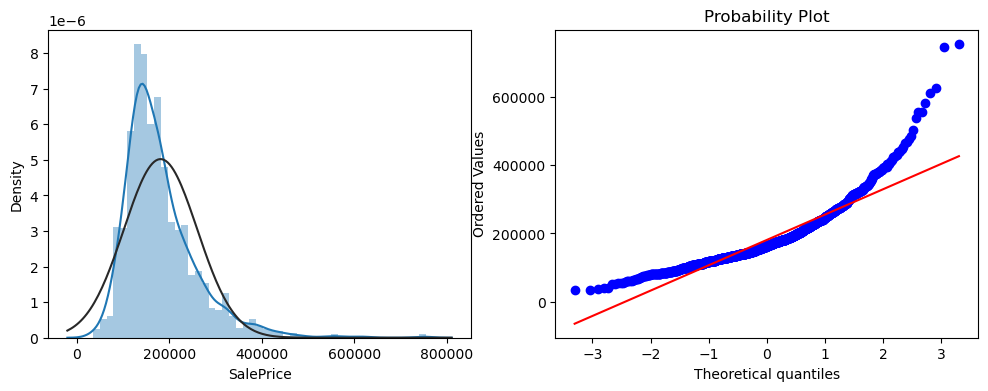

In [25]:
print(df_all.SalePrice.describe())

plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
sns.distplot(df_all.SalePrice.dropna() , fit=stats.norm);
plt.subplot(1,2,2)
_=stats.probplot(df_all.SalePrice.dropna(), plot=plt)

## Log Transform SalePrice

Many models make assumptions about having normally distributed variables, and the long tail above could hurt the performance of the model fitting later. Log transforming SalePrice has the double benefit of significantly improving its normality, and being more relevant for the leaderboard evolution metric

count    1460.000000
mean       12.024051
std         0.399452
min        10.460242
25%        11.775097
50%        12.001505
75%        12.273731
max        13.534473
Name: SalePrice, dtype: float64

/var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/ipykernel_73466/3144468652.py:9: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(sp.dropna() , fit=stats.norm);


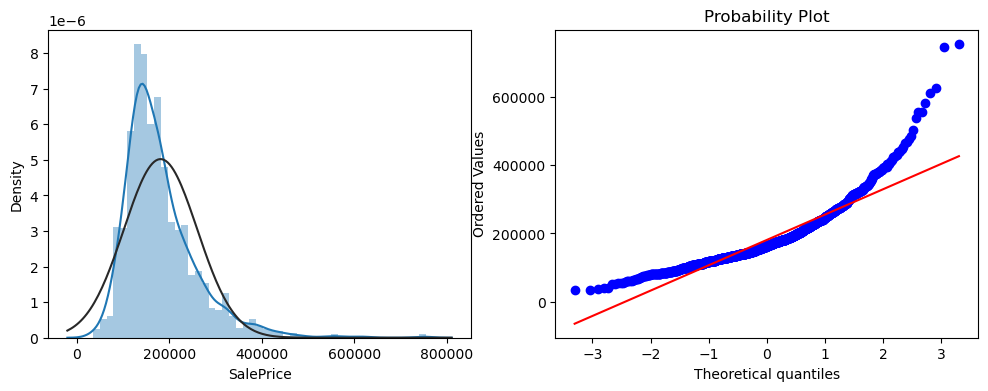

In [27]:
#Log Transform SalePrice to improve normality
sp = df_all.SalePrice
df_all.SalePrice = np.log(sp)

print(df_all.SalePrice.describe())

plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
sns.distplot(sp.dropna() , fit=stats.norm);
plt.subplot(1,2,2)
_=stats.probplot(sp.dropna(), plot=plt)

## Identify Types of Features

Different types of features will need to be treated differently when digging deeper into the data. Here we identify three types of features:
- Numeric-discrete: Numeric features with less than 13 unique values, such as month of the year, or the numeric scales created above
- Numeric-continuous: Numeric features with 13 or more unique values, such as areas, the year a property was built, etc.
- Categorical: The remaining non-numeric features

In [29]:
# extract names of numeric columns
dtypes = df_all.dtypes
cols_numeric = dtypes[dtypes != object].index.tolist()

# MSubClass should be treated as categorical
cols_numeric.remove('MSSubClass')

# choose any numeric column with less than 13 values to be
# "discrete". 13 chosen to include months of the year.
# other columns "continuous"
col_nunique = dict()

for col in cols_numeric:
    col_nunique[col] = df_all[col].nunique()
    
col_nunique = pd.Series(col_nunique)

cols_discrete = col_nunique[col_nunique<13].index.tolist()
cols_continuous = col_nunique[col_nunique>=13].index.tolist()

print(len(cols_numeric),'numeric columns, of which',
      len(cols_continuous),'are continuous and',
      len(cols_discrete),'are discrete.')

81 numeric columns, of which 37 are continuous and 44 are discrete.


In [30]:
# extract names of categorical columns
cols_categ = dtypes[~dtypes.index.isin(cols_numeric)].index.tolist()

for col in cols_categ:
    df_all[col] = df_all[col].astype('category')
    
print(len(cols_categ),'categorical columns.')

26 categorical columns.


## Distribution of SalePrice in Cagegorical Variables

Starting with the categorical variables, let's get a better idea of what the data looks like, and which features might be the most important for predicting sale price. Here we make use of seaborn's violinplot function, which nicely shows how the distribution and mean of the sale price changes for different categories within each feature. 

At this point it's difficult to say much other than there are definitely some values that have a large effect on sale price, e.g., properities in commercial zoning areas (MSZoning == 'C(all)') have much lower sale prices on average. But there is also generally a large spread in sale prices within any single feature category value

/var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/ipykernel_73466/2583003554.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  order = d.groupby(col)['SalePrice'].median().sort_values().index
/var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/ipykernel_73466/2583003554.py:27: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(
/var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/ipykernel_73466/2583003554.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  order = d.groupby(col)['SalePrice'].median().sort_value

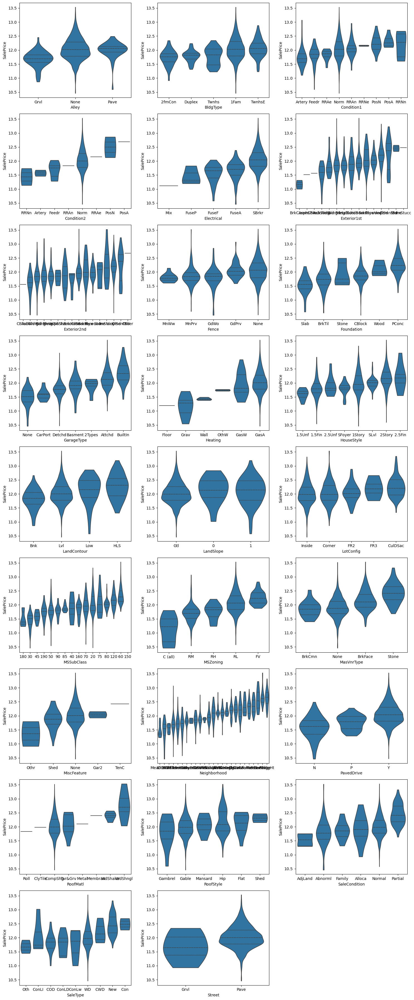

In [32]:
from math import ceil
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

fcols = 3
frows = ceil(len(cols_categ) / fcols)
plt.figure(figsize=(15, 4 * frows))

for i, col in enumerate(cols_categ):
    plt.subplot(frows, fcols, i + 1)

    # mask rows that have both category and SalePrice present
    mask = df_all[col].notna() & df_all['SalePrice'].notna()
    d = df_all.loc[mask, [col, 'SalePrice']]

    # if the "categorical" column is numeric with few uniques, cast to string so seaborn treats it as discrete
    if pd.api.types.is_numeric_dtype(d[col]) and d[col].nunique() <= 20:
        d[col] = d[col].astype('category').astype(str)

    # optional: order categories by median SalePrice (comment out if not desired)
    try:
        order = d.groupby(col)['SalePrice'].median().sort_values().index
    except Exception:
        order = None

    sns.violinplot(
        data=d, x=col, y='SalePrice',
        order=order, inner='quartile', cut=0, scale='width'
    )
    plt.xlabel(col)
    plt.ylabel('SalePrice')

plt.tight_layout()


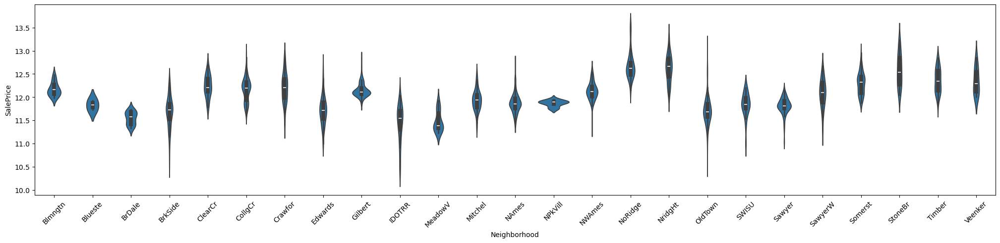

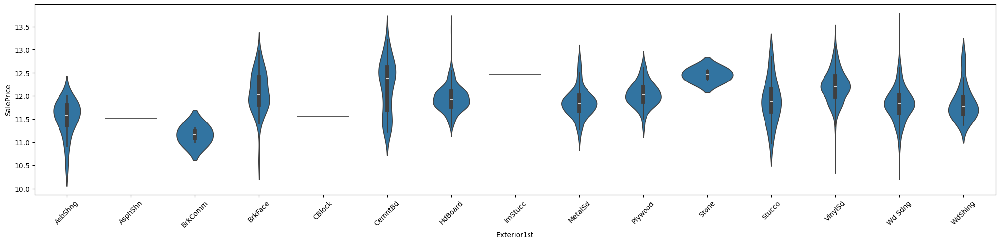

In [33]:
# few bigger plots for features with too many categories to see above

#Neighbourhood
plt.figure(figsize=(25,5))
sns.violinplot(x='Neighborhood',y='SalePrice',data=df_all)
plt.xticks(rotation=45);

#Exterior1st
plt.figure(figsize=(25,5))
sns.violinplot(x='Exterior1st',y='SalePrice',data=df_all)
plt.xticks(rotation=45);

## Significance of Categorical Features for SalePrice

To get a better idea of the importance of each categorical variable for sale price prediction we perform an ANOVA test. We wrote our own function here (apart from obtaining the p-value at the end), as a learning exercise. We can do it directly with scipy.stats.f_oneway

Almost all the categorical features show a significant effect on sale price, with Neighborhood, GarageType, MSubClass (type of dwelling) and Foundation apparently the most important. 

In [35]:
# anova test to check significance of variation in column 'group' vs. column 'value' 
def anova(group,value):
    # select columns of interest, and remove any rows with nan values
    data = df_all[[group,value]]
    data = data[~(data[group].isnull() | data[value].isnull())]
    
    # stats across all data
    tot_groups = data[group].nunique() # no. of groups
    len_data = len(data) # total sample size of houses (all groups)
    mean_data = data[value].mean() # mean across all groups
    df_betwn = tot_groups - 1 # degrees of freedom betwn grps
    df_within = len_data - tot_groups # degrees of freedom within grps
    
    # per group stats
    n_in_group = data.groupby(group)[value].count() # no. houses in group
    mean_group = data.groupby(group)[value].mean() # mean value in this group
    
    # between-group variability
    betwn_var = n_in_group*((mean_group - mean_data)**2)
    betwn_var = float(betwn_var.sum())/df_betwn
    
    # within-group variability
    within_var = 0
    for grp in data[group].unique():
        samples = data.loc[data[group]==grp, value]
        within_var += ((samples-mean_group[grp])**2).sum()
        
    within_var = float(within_var)/df_within
    
    #F-test statistic
    F = betwn_var/within_var
    
    # p-value
    p = stats.f.sf(F, df_betwn, df_within)
    
    return p 

In [36]:
# check significance of categorical variables on SalePrice
p_col = dict()

for col in cols_categ:
    p_col[col] = anova(col,'SalePrice')
    
pd.Series(p_col).sort_values()

/var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/ipykernel_73466/2170950033.py:15: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  n_in_group = data.groupby(group)[value].count() # no. houses in group
/var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/ipykernel_73466/2170950033.py:16: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean_group = data.groupby(group)[value].mean() # mean value in this group
/var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/ipykernel_73466/2170950033.py:15: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed

Neighborhood     4.043304e-243
GarageType       8.427845e-125
MSSubClass       5.096023e-115
Foundation       1.350671e-111
MasVnrType        1.670061e-65
MSZoning          1.021343e-59
Exterior1st       1.053128e-53
Exterior2nd       2.429938e-49
SaleCondition     1.689708e-41
SaleType          5.497893e-36
PavedDrive        1.090995e-31
Electrical        6.081144e-31
HouseStyle        1.636077e-30
Fence             6.560319e-13
RoofStyle         1.705740e-12
BldgType          3.436794e-12
Condition1        1.173444e-10
Alley             1.358108e-09
Heating           2.484312e-09
LandContour       3.086224e-08
LotConfig         6.214575e-07
RoofMatl          4.504239e-04
MiscFeature       6.059928e-03
Condition2        1.382042e-02
Street            2.837931e-02
LandSlope         3.388375e-01
dtype: float64

## Distribution of SalePrice in Discrete Numeric Features

Now let's repeat the same process for the discrete numeric features. In this case some relationships are obvioius, e.g., the sale price is strongly dependent on the overall quality (OverallQual) of a property. Alternatively, the month of sale seems to have no effect

/var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/ipykernel_73466/3523175167.py:27: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(
/var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/ipykernel_73466/3523175167.py:27: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(
/var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/ipykernel_73466/3523175167.py:27: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(
/var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/ipykernel_73466/3523175167.py:27: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(
/var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T

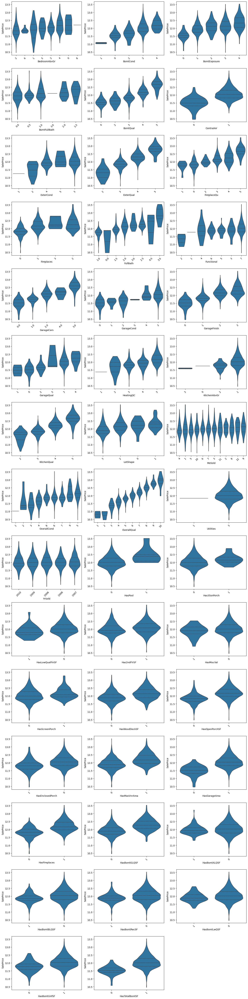

In [38]:
from math import ceil
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

fcols = 3
frows = ceil(len(cols_discrete) / fcols)
plt.figure(figsize=(15, 4 * frows))

for i, col in enumerate(cols_discrete):
    plt.subplot(frows, fcols, i + 1)

    # keep rows with both values present (important if SalePrice has NaNs)
    mask = df_all[col].notna() & df_all['SalePrice'].notna()
    d = df_all.loc[mask, [col, 'SalePrice']].copy()

    # if numeric with small cardinality, coerce to categorical strings
    if pd.api.types.is_numeric_dtype(d[col]) and d[col].nunique() <= 20:
        d[col] = d[col].astype('category').astype(str)

    # optional: order by median SalePrice for readability
    try:
        order = d.groupby(col)['SalePrice'].median().sort_values().index
    except Exception:
        order = None

    sns.violinplot(
        data=d, x=col, y='SalePrice',
        order=order, inner='quartile', cut=0, scale='width'
    )
    plt.xlabel(col)
    plt.ylabel('SalePrice')
    plt.xticks(rotation=45)

plt.tight_layout()

## Significance of Discrete Numeric Features for SalePrice

Performing ANOVA tests on the discrete variables give sensible results based on what's observed above. The dependence on overall quality is so strong it registers as a p-value of zero.

In [40]:
p_col = dict()

for col in cols_discrete:
    p_col[col] = anova(col,'SalePrice')

pd.Series(p_col).sort_values()

OverallQual          0.000000e+00
GarageCars          5.539585e-211
ExterQual           6.935425e-195
BsmtQual            2.031282e-188
KitchenQual         4.441486e-187
FullBath            3.733271e-167
GarageFinish        4.057458e-151
FireplaceQu         6.963458e-115
HasFireplaces        1.688600e-97
Fireplaces           7.485912e-97
HeatingQC            1.614882e-82
HasOpenPorchSF       2.024867e-73
HasBsmtGLQSF         3.828370e-69
OverallCond          9.270535e-53
HasMasVnrArea        5.246135e-52
GarageCond           2.508058e-47
BsmtExposure         2.590707e-47
GarageQual           6.068406e-46
CentralAir           9.855628e-44
HasGarageArea        8.411473e-37
HasWoodDeckSF        3.391236e-36
LotShape             7.856968e-29
BsmtCond             1.492754e-27
BedroomAbvGr         2.473588e-20
BsmtFullBath         2.301539e-17
HasEnclosedPorch     5.905933e-17
HasTotalBsmtSF       1.370151e-14
ExterCond            6.540305e-14
HasBsmtUnfSF         1.603646e-13
Has2ndFlrSF   

## Distribution of Continuous Variables and Effect on SalePrice

Finally - the continuous variables. For these I revert back to scatter plots and standard histograms. Some strong relationships are immediately clear - for example between the TotalAreaSF feature created earlier and the sale price. The nuisance caused by zeroes and/or outliers can again be seen by the poor quality regression lines in LotArea, for example

/var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/ipykernel_73466/1144057492.py:18: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df_all[col].dropna() , fit=stats.norm)
/var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/ipykernel_73466/1144057492.py:18: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot




In [42]:
# figure parameters
fcols = 2
frows = len(cols_continuous)
plt.figure(figsize=(5*fcols,4*frows))

i=0
for col in cols_continuous:
    i+=1
    ax=plt.subplot(frows,fcols,i)
    sns.regplot(x=col, y='SalePrice', data=df_all, ax=ax, 
                scatter_kws={'marker':'.','s':3,'alpha':0.3},
                line_kws={'color':'k'});
    plt.xlabel(col)
    plt.ylabel('SalePrice')
    
    i+=1
    ax=plt.subplot(frows,fcols,i)
    sns.distplot(df_all[col].dropna() , fit=stats.norm)
    plt.xlabel(col)

## Correlation Between Numeric Features

For all the numeric features (discrete and continuous) let's check the correlation with sale price. We've used the Spearman correlation coefficient, which is more resiliant to identifying non-linear relationships than Pearson. We also consider only the absolute value of the coefficient, as we're interested in finding the strongest relationship, not whether they are positively/negatively correlated. 

The most correlated features relate to the overall size and quality of the house. Having a garage also seems important, as well as the age of the property. The least correlated features tend to be those that appear in very few or almost all properties - for example nearly all houses have the full range of utilities, but very few have a pool. It's more surprising that the condition of a house does not seem very important for sale price - the distinction between that and the quality of a house isn't particularly clear. 

SalePrice        1.000000
TotalAreaSF      0.834994
OverallQual      0.809829
LivingAreaSF     0.753706
GrLivArea        0.731310
GarageCars       0.690711
ExterQual        0.684014
BsmtQual         0.678026
FullBath         0.675455
KitchenQual      0.672849
YearBuilt        0.652682
GarageArea       0.649379
GarageFinish     0.633974
GarageYrBlt      0.612604
TotalBsmtSF      0.602725
1stFlrSF         0.575408
YearRemodAdd     0.571159
FireplaceQu      0.537602
TotRmsAbvGrd     0.532586
HasFireplaces    0.525735
Name: SalePrice, dtype: float64
-----------------
LowQualFinSF    0.067719
Has3SsnPorch    0.065329
HasMiscVal      0.063389
MiscVal         0.062727
BsmtALQSF       0.061374
HasPool         0.058428
BsmtUnfFrac     0.036628
YrSold          0.029899
Utilities       0.016710
ExterCond       0.011682
Name: SalePrice, dtype: float64


<Axes: >

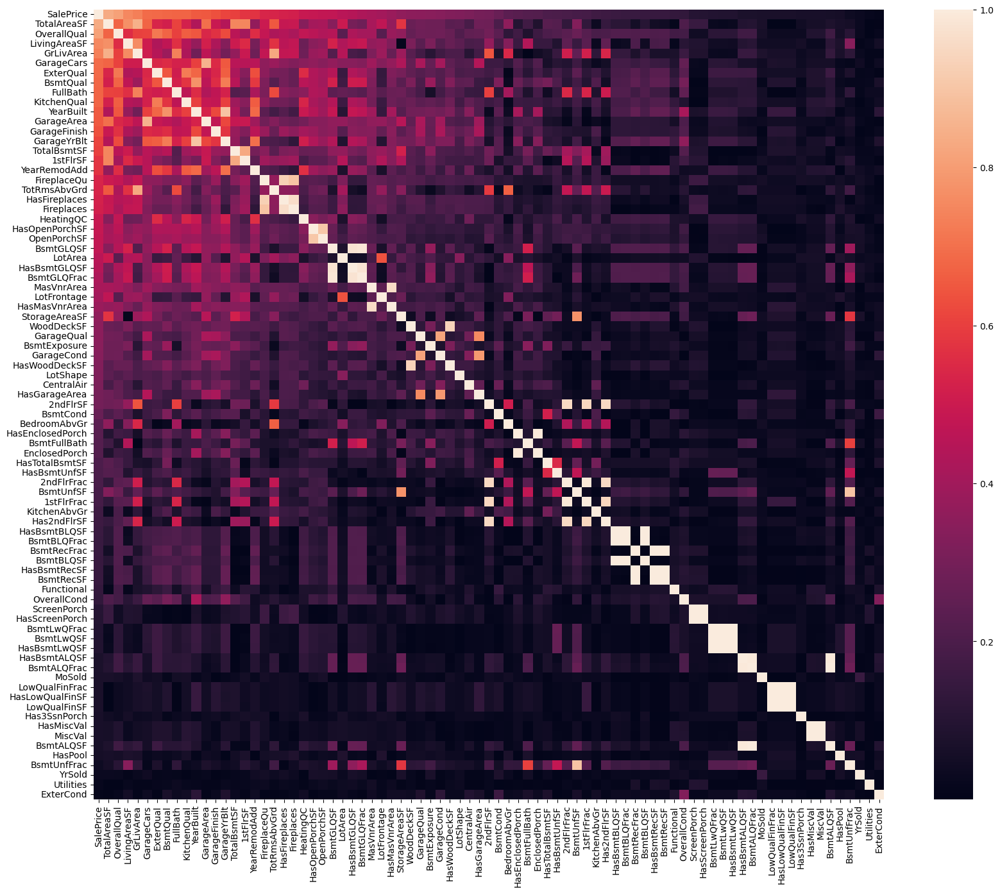

In [44]:
# correlation between numeric variables
df_corr = df_all.loc[id_train, cols_numeric].corr(method='spearman').abs()

# order columns and rows by correlation with SalePrice
df_corr = df_corr.sort_values('SalePrice',axis=0,ascending=False).sort_values('SalePrice',axis=1,ascending=False)

print(df_corr.SalePrice.head(20))
print('-----------------')
print(df_corr.SalePrice.tail(10))

ax=plt.figure(figsize=(20,16)).gca()
sns.heatmap(df_corr,ax=ax,square=True)

## Collinearity

As can be seen in the heatmap above, many of the features are correlated with each other. Some of these are clear - for example the area of a garage and the number of cars it can hold are clearly related. This relationship is plotted below, although the distinction maybe isn't as clear as expected - there is a garage with capacity for 1 car that has an area bigger than many of the garages with capacity for 4 cars, for example. 

A lot of the features we created earlier, such as the dummy variables that indicate whether a feature is present or not, are naturally highly correlated with the features they represent. 

Having collinear features can make it more difficult for our models to identify which parameters are truly important. Some of the features, like garage area, provide very little extra information and probably could be removed. However, we have taken the lazy approach, kept all the features, and relied on the models to do a decent job at picking out which features to use. 

But this is definitely something that could be looked at to improve. And removing some features may help some of the more complicated models get better results.

<Axes: xlabel='GarageCars', ylabel='GarageArea'>

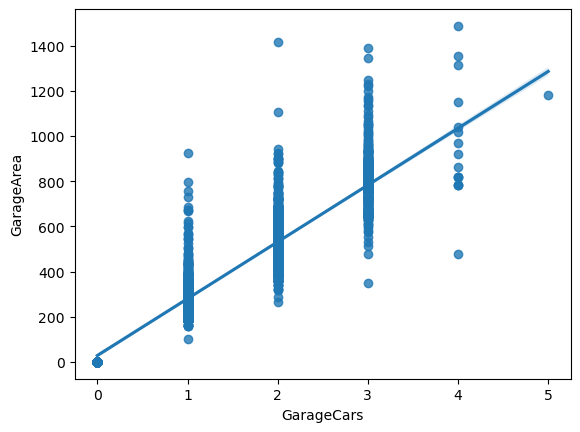

In [46]:
sns.regplot(x='GarageCars',y='GarageArea',data=df_all)

## Normalize numeric Features

As we have features with very different scales (such as areas and counts), we normalize all the numeric features using a simple function defined earlier (in the LotFrontage NaN values section - though again there are built-in functions in sklearn that could do this) to lie between zero and one. This helps to prevent the model from being biased towards certain features.

In [48]:
# normalise numeric columns
scale_cols = [col for col in cols_numeric if col!='SalePrice']

df_all[scale_cols] = df_all[scale_cols].apply(scale_minmax,axis=0)

df_all[scale_cols].describe()

,1stFlrSF,2ndFlrSF,BedroomAbvGr,BsmtCond,BsmtExposure,BsmtFullBath,BsmtQual,BsmtUnfSF,CentralAir,EnclosedPorch,...,HasMasVnrArea,HasGarageArea,HasFireplaces,HasBsmtGLQSF,HasBsmtALQSF,HasBsmtBLQSF,HasBsmtRecSF,HasBsmtLwQSF,HasBsmtUnfSF,HasTotalBsmtSF
count,2919.000000,2919.000000,2919.000000,2919.000000,2919.000000,2919.000000,2919.000000,2919.000000,2919.000000,2919.000000,...,2919.000000,2919.000000,2919.000000,2919.000000,2919.000000,2919.000000,2919.000000,2919.000000,2919.000000,2919.000000
mean,0.173405,0.162946,0.357528,0.729616,0.405961,0.153420,0.695512,0.239974,0.932854,0.022824,...,0.396711,0.945872,0.513532,0.302501,0.164782,0.114765,0.134635,0.082563,0.917095,0.972936
std,0.082412,0.207604,0.102837,0.143737,0.267506,0.173593,0.181090,0.188181,0.250318,0.063482,...,0.489299,0.226309,0.499902,0.459420,0.371048,0.318793,0.341392,0.275267,0.275786,0.162298
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.113842,0.000000,0.250000,0.750000,0.250000,0.000000,0.600000,0.094178,1.000000,0.000000,...,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000
50%,0.157110,0.000000,0.375000,0.750000,0.250000,0.000000,0.800000,0.199914,1.000000,0.000000,...,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000
75%,0.221277,0.340920,0.375000,0.750000,0.500000,0.333333,0.800000,0.344606,1.000000,0.000000,...,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## Which Numeric Features are Candidates to be Transformed?

Like we did for SalePrice, we can transform the continuous numeric features to try to improve their normality. For SalePrice we used a simple log transform, but here we try the more flexible Box-Cox transform, letting the scipy.stats.boxcox function optimize the parameters of the fit in each case. 

Here we plot the original and transformed distributions for all the continuous features to identify which transformations look reasonable. 

/var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/ipykernel_73466/2491793070.py:13: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(dat[var] , fit=stats.norm);
/var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/ipykernel_73466/2491793070.py:33: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(trans_var 




In [50]:
#Check effect of Box-Cox transforms on distributions of continuous variables
fcols = 6
frows = len(cols_continuous)-1
plt.figure(figsize=(4*fcols,4*frows))
i=0

for var in cols_continuous:
    if var!='SalePrice':
        dat = df_all[[var, 'SalePrice']].dropna()
        
        i+=1
        plt.subplot(frows,fcols,i)
        sns.distplot(dat[var] , fit=stats.norm);
        plt.title(var+' Original')
        plt.xlabel('')
        
        i+=1
        plt.subplot(frows,fcols,i)
        _=stats.probplot(dat[var], plot=plt)
        plt.title('skew='+'{:.4f}'.format(stats.skew(dat[var])))
        plt.xlabel('')
        plt.ylabel('')
        
        i+=1
        plt.subplot(frows,fcols,i)
        plt.plot(dat[var], dat['SalePrice'],'.',alpha=0.5)
        plt.title('corr='+'{:.2f}'.format(np.corrcoef(dat[var], dat['SalePrice'])[0][1]))
 
        i+=1
        plt.subplot(frows,fcols,i)
        trans_var, lambda_var = stats.boxcox(dat[var].dropna()+1)
        trans_var = scale_minmax(trans_var)      
        sns.distplot(trans_var , fit=stats.norm);
        plt.title(var+' Tramsformed')
        plt.xlabel('')
        
        i+=1
        plt.subplot(frows,fcols,i)
        _=stats.probplot(trans_var, plot=plt)
        plt.title('skew='+'{:.4f}'.format(stats.skew(trans_var)))
        plt.xlabel('')
        plt.ylabel('')
        
        i+=1
        plt.subplot(frows,fcols,i)
        plt.plot(trans_var, dat['SalePrice'],'.',alpha=0.5)
        plt.title('corr='+'{:.2f}'.format(np.corrcoef(trans_var,dat['SalePrice'])[0][1]))

## Box-Cox Transform Suitable Variables

The transformation doesn't help, and in some cases degrades, some of the variables, usually because of those pesky zeros again. For example, 2ndFlrSF has many zeros for properties that don't have a second floor. The transformation in this case doesn't achieve much other than separating the zeros and non-zero points by a greater margin.

By inspecting all the plots above, we define a list of features for which the transform doesn't help. We transform then re-normalize the remaining features.

In [52]:
# variables not suitable for box-cox transformation based on above (usually due to excessive zeros)
cols_notransform = ['2ndFlrSF','1stFlrFrac','2ndFlrFrac','StorageAreaSF',
                    'EnclosedPorch','LowQualFinSF','MasVnrArea',
                    'MiscVal','ScreenPorch','OpenPorchSF','WoodDeckSF','SalePrice',
                    'BsmtGLQSF','BsmtALQSF','BsmtBLQSF','BsmtRecSF','BsmtLwQSF','BsmtUnfSF',
                    'BsmtGLQFrac','BsmtALQFrac','BsmtBLQFrac','BsmtRecFrac','BsmtLwQFrac','BsmtUnfFrac']

cols_transform = [col for col in cols_continuous if col not in cols_notransform]

#transform remaining variables
print('Transforming',len(cols_transform),'columns:',cols_transform)

for col in cols_transform:   
    # transform column
    df_all.loc[:,col], _ = stats.boxcox(df_all.loc[:,col]+1)
    
    # renormalise column
    df_all.loc[:,col] = scale_minmax(df_all.loc[:,col])

Transforming 13 columns: ['1stFlrSF', 'GarageArea', 'GarageYrBlt', 'GrLivArea', 'LotArea', 'LotFrontage', 'TotRmsAbvGrd', 'TotalBsmtSF', 'YearBuilt', 'YearRemodAdd', 'LowQualFinFrac', 'TotalAreaSF', 'LivingAreaSF']


## Prepare Data for Model Fitting

Almost time to start fitting some models, all that's left to do is to figure out what to do with the remaining categorical features. We decided to use one-hot encoding (creating a binary indicator for each possible feature variable), which is very easy to obtain with the pandas.DataFrame.get_dummies function. This ends up increasing the number of variables in the dataset from about 100 to around 250. 

In [54]:
# select features, encode categoricals, create dataframe for model fitting

# select which features to use (all for now)
model_cols = df_all.columns

# encode categoricals
df_model = pd.get_dummies(df_all[model_cols])

# Rather than including Condition1 and Condition2, or Exterior1st and Exterior2nd,
# combine the dummy variables (allowing 2 true values per property)
if ('Condition1' in model_cols) and ('Condition2' in model_cols):
    
    cond_suffix = ['Artery','Feedr','Norm','PosA','PosN','RRAe','RRAn','RRNn']
    
    for suffix in cond_suffix:
        col_cond1 = 'Condition1_'+suffix
        col_cond2 = 'Condition2_'+suffix
        
        df_model[col_cond1] = df_model[col_cond1] | df_model[col_cond2]
        df_model.drop(col_cond2,axis=1,inplace=True)
        
if ('Exterior1st' in model_cols) and ('Exterior2nd' in model_cols):
    
    # some different strings in Exterior1st and Exterior2nd for same type - rename columns to correct
    df_model.rename(columns={'Exterior2nd_Wd Shng':'Exterior2nd_WdShing',
                             'Exterior2nd_Brk Cmn':'Exterior2nd_BrkComm',
                             'Exterior2nd_CmentBd':'Exterior2nd_CemntBd'},inplace=True)

    ext_suffix = ['AsphShn','BrkComm','BrkFace','CBlock','CemntBd',
                    'HdBoard','ImStucc','MetalSd','Plywood','Stone',
                    'Stucco','VinylSd','Wd Sdng','WdShing','AsbShng']
    
    for suffix in ext_suffix:
        col_cond1 = 'Exterior1st_'+suffix
        col_cond2 = 'Exterior2nd_'+suffix
        
        df_model[col_cond1] = df_model[col_cond1] | df_model[col_cond2]
        df_model.drop(col_cond2,axis=1,inplace=True)
        
display(df_model.head())

,1stFlrSF,2ndFlrSF,BedroomAbvGr,BsmtCond,BsmtExposure,BsmtFullBath,BsmtQual,BsmtUnfSF,CentralAir,EnclosedPorch,...,SaleType_CWD,SaleType_Con,SaleType_ConLD,SaleType_ConLI,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,Street_Grvl,Street_Pave
Id,,,,,,,,,,,,,,,,,,,,,
1,0.362867,0.413559,0.375,0.75,0.25,0.333333,0.8,0.064212,1.0,0.000000,...,False,False,False,False,False,False,False,True,False,True
2,0.543162,0.000000,0.375,0.75,1.00,0.166667,0.8,0.121575,1.0,0.000000,...,False,False,False,False,False,False,False,True,False,True
3,0.395939,0.419370,0.375,0.75,0.50,0.333333,0.8,0.185788,1.0,0.000000,...,False,False,False,False,False,False,False,True,False,True
4,0.416107,0.366102,0.375,1.00,0.25,0.333333,0.6,0.231164,1.0,0.268775,...,False,False,False,False,False,False,False,True,False,True
5,0.497820,0.509927,0.500,0.75,0.75,0.333333,0.8,0.209760,1.0,0.000000,...,False,False,False,False,False,False,False,True,False,True


In [55]:
# function to get training samples
def get_training_data():
    # extract training samples
    df_train = df_model.loc[id_train]
    
    # split SalePrice and features
    y = df_train.SalePrice
    X = df_train.drop('SalePrice',axis=1)
    
    return X, y

# extract test data (without SalePrice)
def get_test_data():
    return df_model.loc[id_test].drop('SalePrice',axis=1)

## Identify and Remove Outliers

Now time to start fitting some models. First we fit a linear regression Ridge model, because it immediately gives good results with default values. Our goal here is to use a straightforward model to identify any outlying points - properties with sale prices far away from what's expected given their features. 

The function we define below fits the model and checks the residuals between the models' predicted sale prices and the true sale prices. The standard deviation of the residuals is calulated, and the 20 or so properties with residuals greater than three times this standard deviation are removed from the training data so they don't skew the parameters of the fitted models. 

Just Ridge with default values already gives a deceent prediction, which is a promising sign.

In [57]:
# metric for evaluation
def rmse(y_true, y_pred):
    diff = y_pred - y_true
    sum_sq = sum(diff**2)    
    n = len(y_pred)   
    
    return np.sqrt(sum_sq/n)

# scorer to be used in sklearn model fitting
rmse_scorer = make_scorer(rmse, greater_is_better=False)

In [58]:
# function to detect outliers based on the predictions of a model
def find_outliers(model, X, y, sigma=3):

    # predict y values using model
    try:
        y_pred = pd.Series(model.predict(X), index=y.index)
    # if predicting fails, try fitting the model first
    except:
        model.fit(X,y)
        y_pred = pd.Series(model.predict(X), index=y.index)
        
    # calculate residuals between the model prediction and true y values
    resid = y - y_pred
    mean_resid = resid.mean()
    std_resid = resid.std()

    # calculate z statistic, define outliers to be where |z|>sigma
    z = (resid - mean_resid)/std_resid    
    outliers = z[abs(z)>sigma].index
    
    # print and plot the results
    print('R2=',model.score(X,y))
    print('rmse=',rmse(y, y_pred))
    print('---------------------------------------')

    print('mean of residuals:',mean_resid)
    print('std of residuals:',std_resid)
    print('---------------------------------------')

    print(len(outliers),'outliers:')
    print(outliers.tolist())

    plt.figure(figsize=(15,5))
    ax_131 = plt.subplot(1,3,1)
    plt.plot(y,y_pred,'.')
    plt.plot(y.loc[outliers],y_pred.loc[outliers],'ro')
    plt.legend(['Accepted','Outlier'])
    plt.xlabel('y')
    plt.ylabel('y_pred');

    ax_132=plt.subplot(1,3,2)
    plt.plot(y,y-y_pred,'.')
    plt.plot(y.loc[outliers],y.loc[outliers]-y_pred.loc[outliers],'ro')
    plt.legend(['Accepted','Outlier'])
    plt.xlabel('y')
    plt.ylabel('y - y_pred');

    ax_133=plt.subplot(1,3,3)
    z.plot.hist(bins=50,ax=ax_133)
    z.loc[outliers].plot.hist(color='r',bins=50,ax=ax_133)
    plt.legend(['Accepted','Outlier'])
    plt.xlabel('z')
    
    plt.savefig('outliers.png')
    
    return outliers

R2= 0.9383026335539845
rmse= 0.09918568295414383
---------------------------------------
mean of residuals: -3.2375928422219633e-15
std of residuals: 0.09921966811291194
---------------------------------------
19 outliers:
[31, 89, 411, 463, 496, 524, 589, 633, 682, 729, 875, 899, 969, 971, 1183, 1299, 1325, 1433, 1454]


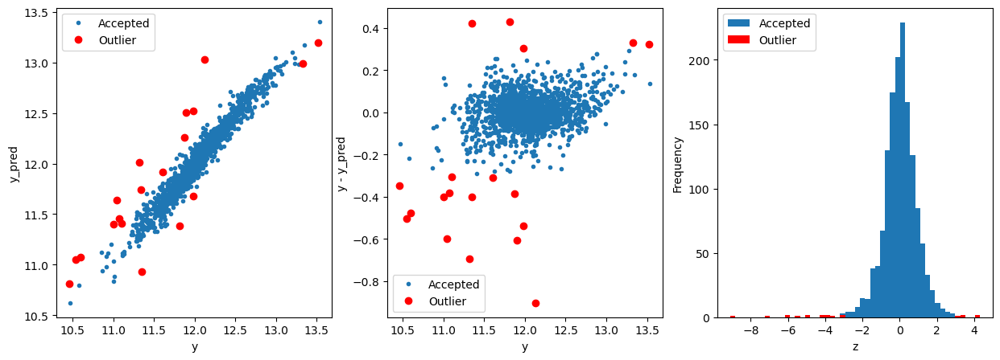

In [59]:
# get training data
X, y = get_training_data()

# find and remove outliers using a Ridge model
outliers = find_outliers(Ridge(), X, y)

# permanently remove these outliers from the data
df_model = df_model.drop(outliers)
id_train = id_train.drop(outliers)

## Fit and Optimize Models

To avoid repeating code we create a function to perform the fitting process for each model type we try. We use k-fold cross-validation to reduce the chances of overfitting the training data - specifically 5-fold cross-validation repeated 5 times. The parameters of each model are optimized using grid search, and the function returns the best model found and some stats on the model performance. 

The models we optimize are: 

Linear Regression:
- sklearn.linear_model.Ridge
- sklearn.linear_model.Lasso
- sklearn.linear_model.ElasticNet

Support Vector Machines:
- sklearn.svm.LinearSVR
- sklearn.svm.SVR

Nearest Neighbors:
- sklearn.neighbors.KNearestNeighborsRegressor

Tree Based:
- sklearn.ensemble.RandomForestRegressor
- sklearn.ensemble.GradientBoostingRegressor
- xgboost.XGBRegressor

There is some trail and error involved in finding the right parameter ranges to search for each model. The current ranges in the notebook contain the optimal values we found whilst being restrictive enough to compute within a few minutes.

In [61]:
def train_model(model, param_grid=[], X=[], y=[], 
                splits=5, repeats=5):

    # get unmodified training data, unless data to use already specified
    if len(y)==0:
        X,y = get_training_data()
    
    # create cross-validation method
    rkfold = RepeatedKFold(n_splits=splits, n_repeats=repeats)
    
    # perform a grid search if param_grid given
    if len(param_grid)>0:
        # setup grid search parameters
        gsearch = GridSearchCV(model, param_grid, cv=rkfold,
                               scoring=rmse_scorer,
                               verbose=1, return_train_score=True)

        # search the grid
        gsearch.fit(X,y)

        # extract best model from the grid
        model = gsearch.best_estimator_        
        best_idx = gsearch.best_index_

        # get cv-scores for best model
        grid_results = pd.DataFrame(gsearch.cv_results_)       
        cv_mean = abs(grid_results.loc[best_idx,'mean_test_score'])
        cv_std = grid_results.loc[best_idx,'std_test_score']

    # no grid search, just cross-val score for given model    
    else:
        grid_results = []
        cv_results = cross_val_score(model, X, y, scoring=rmse_scorer, cv=rkfold)
        cv_mean = abs(np.mean(cv_results))
        cv_std = np.std(cv_results)
    
    # combine mean and std cv-score in to a pandas series
    cv_score = pd.Series({'mean':cv_mean,'std':cv_std})

    # predict y using the fitted model
    y_pred = model.predict(X)
    
    # print stats on model performance         
    print('----------------------')
    print(model)
    print('----------------------')
    print('score=',model.score(X,y))
    print('rmse=',rmse(y, y_pred))
    print('cross_val: mean=',cv_mean,', std=',cv_std)
    
    # residual plots
    y_pred = pd.Series(y_pred,index=y.index)
    resid = y - y_pred
    mean_resid = resid.mean()
    std_resid = resid.std()
    z = (resid - mean_resid)/std_resid    
    n_outliers = sum(abs(z)>3)
    
    plt.figure(figsize=(15,5))
    ax_131 = plt.subplot(1,3,1)
    plt.plot(y,y_pred,'.')
    plt.xlabel('y')
    plt.ylabel('y_pred');
    plt.title('corr = {:.3f}'.format(np.corrcoef(y,y_pred)[0][1]))
    ax_132=plt.subplot(1,3,2)
    plt.plot(y,y-y_pred,'.')
    plt.xlabel('y')
    plt.ylabel('y - y_pred');
    plt.title('std resid = {:.3f}'.format(std_resid))
    
    ax_133=plt.subplot(1,3,3)
    z.plot.hist(bins=50,ax=ax_133)
    plt.xlabel('z')
    plt.title('{:.0f} samples with z>3'.format(n_outliers))

    return model, cv_score, grid_results

In [62]:
# places to store optimal models and scores
opt_models = dict()
score_models = pd.DataFrame(columns=['mean','std'])

# no. k-fold splits
splits=5
# no. k-fold iterations
repeats=5

## Linear Regression

Ridge

Fitting 25 folds for each of 23 candidates, totalling 575 fits
----------------------
Ridge(alpha=1.75)
----------------------
score= 0.9581880124769495
rmse= 0.07929601383472569
cross_val: mean= 0.09548399043040101 , std= 0.004646587747087479


/var/folders/vz/92s_51wn0sd2srv1v27zz1s00000gn/T/ipykernel_73466/2579097000.py:12: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  score_models = pd.concat([score_models, row], axis=0)


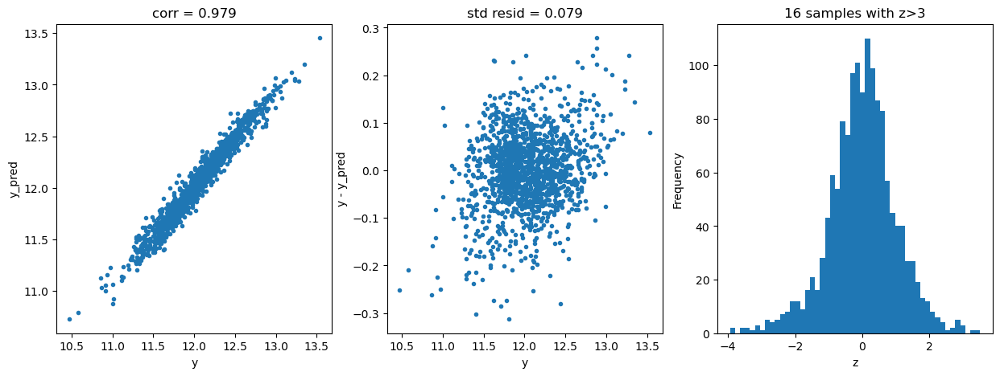

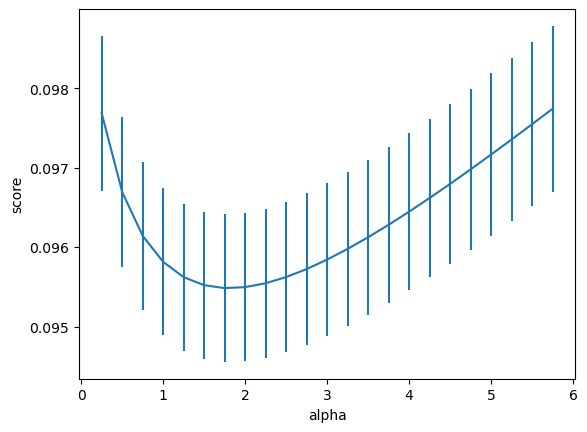

In [64]:
model = 'Ridge'

opt_models[model] = Ridge()
alph_range = np.arange(0.25,6,0.25)
param_grid = {'alpha': alph_range}

opt_models[model],cv_score,grid_results = train_model(opt_models[model], param_grid=param_grid, 
                                              splits=splits, repeats=repeats)

row = cv_score.to_frame().T               # Series -> 1-row DataFrame
row.index = [model]
score_models = pd.concat([score_models, row], axis=0)

plt.figure()
plt.errorbar(alph_range, abs(grid_results['mean_test_score']),
             abs(grid_results['std_test_score'])/np.sqrt(splits*repeats))
plt.xlabel('alpha')
plt.ylabel('score');

## Lasso

Fitting 25 folds for each of 23 candidates, totalling 575 fits
----------------------
Lasso(alpha=0.00022000000000000003)
----------------------
score= 0.9552724688441162
rmse= 0.0820140792437372
cross_val: mean= 0.09315798008775163 , std= 0.004492051488269537


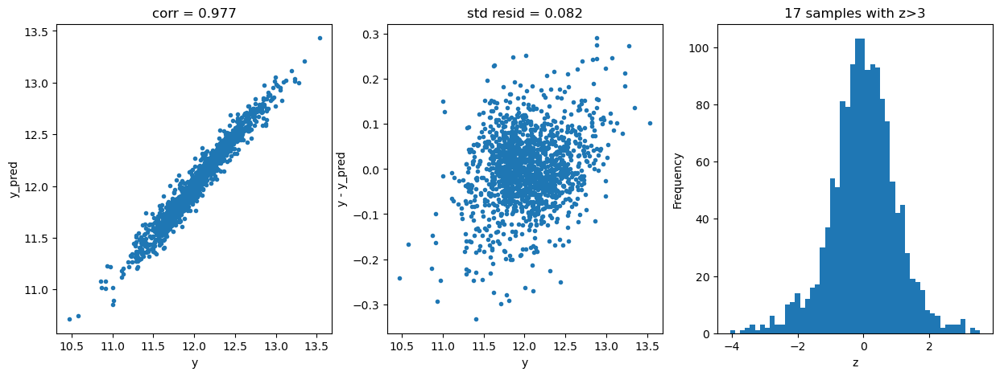

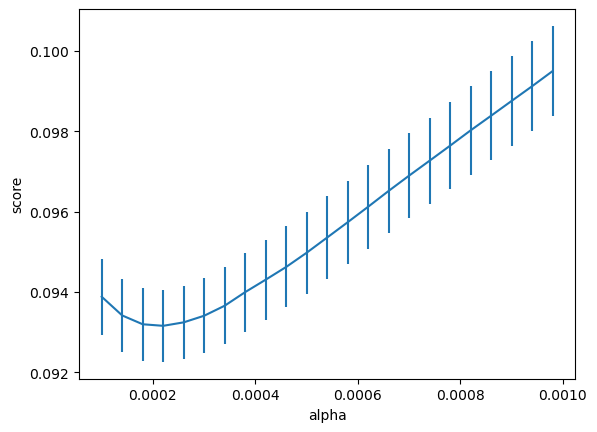

In [66]:
model = 'Lasso'

opt_models[model] = Lasso()
alph_range = np.arange(1e-4,1e-3,4e-5)
param_grid = {'alpha': alph_range}

opt_models[model], cv_score, grid_results = train_model(opt_models[model], param_grid=param_grid, 
                                              splits=splits, repeats=repeats)

row = cv_score.to_frame().T               # Series -> 1-row DataFrame
row.index = [model]
score_models = pd.concat([score_models, row], axis=0)

plt.figure()
plt.errorbar(alph_range, abs(grid_results['mean_test_score']),abs(grid_results['std_test_score'])/np.sqrt(splits*repeats))
plt.xlabel('alpha')
plt.ylabel('score');

## ElasticNet

Fitting 25 folds for each of 81 candidates, totalling 2025 fits
----------------------
ElasticNet(alpha=0.00030000000000000003, l1_ratio=0.9, max_iter=100000)
----------------------
score= 0.9542847739773848
rmse= 0.08291467174543647
cross_val: mean= 0.09272823654471654 , std= 0.004686054914326083


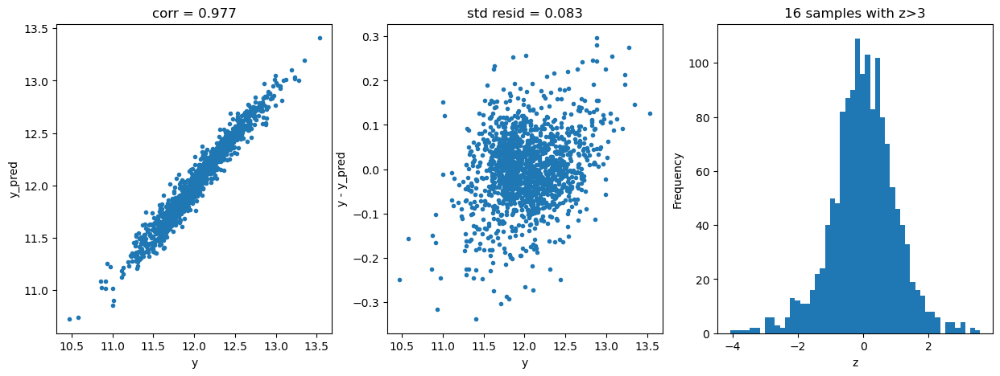

In [68]:
model ='ElasticNet'
opt_models[model] = ElasticNet()

param_grid = {'alpha': np.arange(1e-4,1e-3,1e-4),
              'l1_ratio': np.arange(0.1,1.0,0.1),
              'max_iter':[100000]}

opt_models[model], cv_score, grid_results = train_model(opt_models[model], param_grid=param_grid, 
                                              splits=splits, repeats=repeats)

row = cv_score.to_frame().T               # Series -> 1-row DataFrame
row.index = [model]
score_models = pd.concat([score_models, row], axis=0)

## SVM

Linear

Fitting 25 folds for each of 9 candidates, totalling 225 fits


/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/

----------------------
LinearSVR(C=0.6000000000000001, max_iter=100000)
----------------------
score= 0.9543394763788082
rmse= 0.08286504944573259
cross_val: mean= 0.10637873565669928 , std= 0.010035182182418653


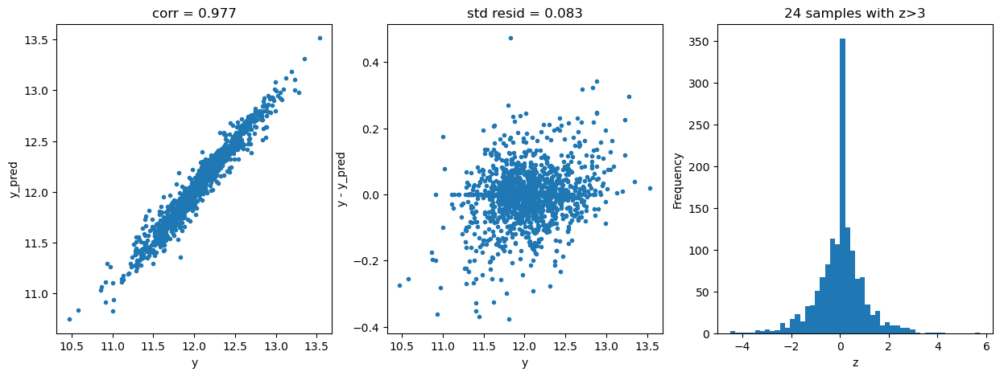

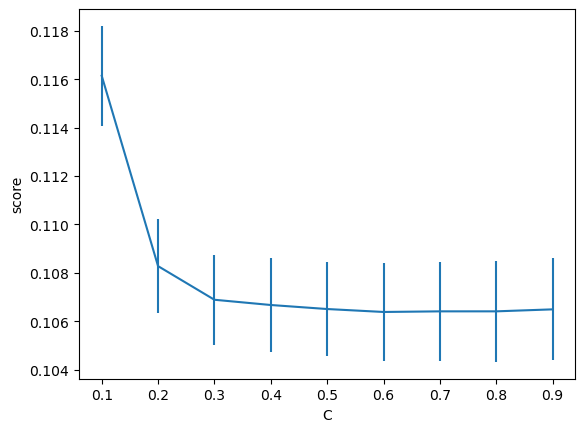

In [70]:
model='LinearSVR'
opt_models[model] = LinearSVR()

crange = np.arange(0.1,1.0,0.1)
param_grid = {'C':crange,
             'max_iter':[100000]}

opt_models[model], cv_score, grid_results = train_model(opt_models[model], param_grid=param_grid, 
                                              splits=splits, repeats=repeats)

row = cv_score.to_frame().T               # Series -> 1-row DataFrame
row.index = [model]
score_models = pd.concat([score_models, row], axis=0)

plt.figure()
plt.errorbar(crange, abs(grid_results['mean_test_score']),abs(grid_results['std_test_score'])/np.sqrt(splits*repeats))
plt.xlabel('C')
plt.ylabel('score');

Non-Linear

Fitting 5 folds for each of 30 candidates, totalling 150 fits
----------------------
SVR(C=15, gamma='auto')
----------------------
score= 0.9648720839330447
rmse= 0.07268204584503804
cross_val: mean= 0.09925180524746006 , std= 0.003537519933445408


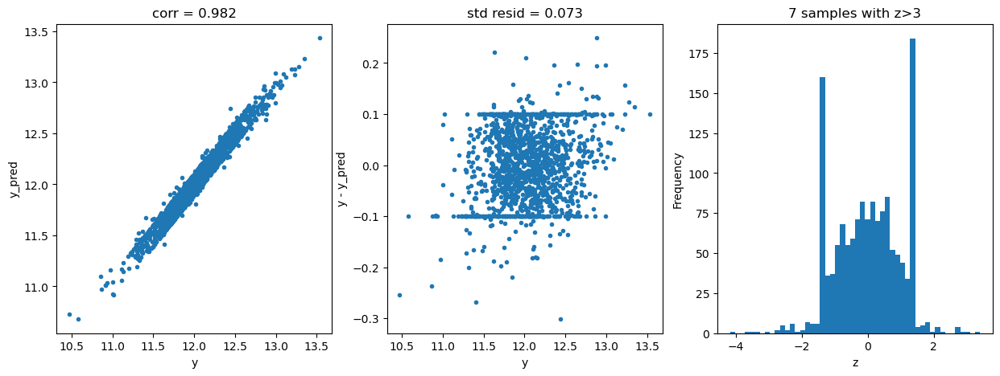

In [72]:
model ='SVR'
opt_models[model] = SVR()

param_grid = {'C':np.arange(1,21,2),
              'kernel':['poly','rbf','sigmoid'],
              'gamma':['auto']}

opt_models[model], cv_score, grid_results = train_model(opt_models[model], param_grid=param_grid, 
                                              splits=splits, repeats=1)

row = cv_score.to_frame().T               # Series -> 1-row DataFrame
row.index = [model]
score_models = pd.concat([score_models, row], axis=0)


## KNeighbors

Fitting 5 folds for each of 8 candidates, totalling 40 fits
----------------------
KNeighborsRegressor(n_neighbors=4)
----------------------
score= 0.8733279862287857
rmse= 0.13801976622519
cross_val: mean= 0.18366926626687968 , std= 0.006899959593351154


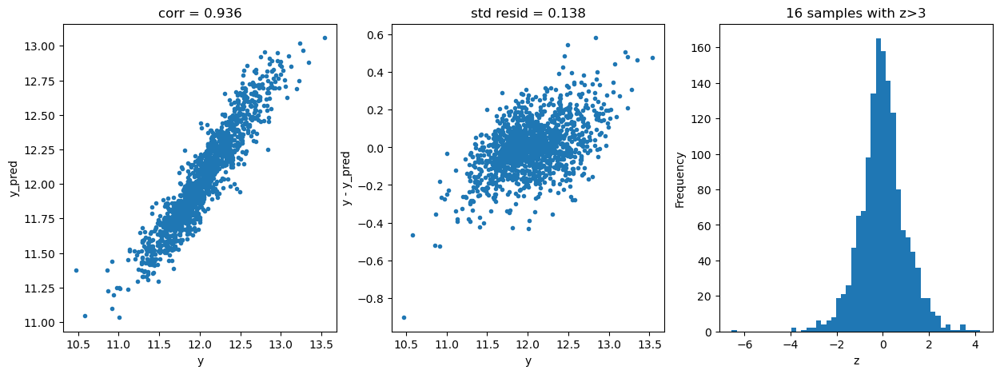

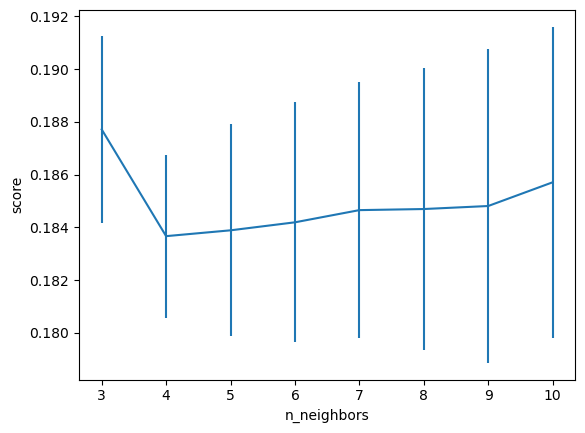

In [74]:
model = 'KNeighbors'
opt_models[model] = KNeighborsRegressor()

param_grid = {'n_neighbors':np.arange(3,11,1)}

opt_models[model], cv_score, grid_results = train_model(opt_models[model], param_grid=param_grid, 
                                              splits=splits, repeats=1)

row = cv_score.to_frame().T               # Series -> 1-row DataFrame
row.index = [model]
score_models = pd.concat([score_models, row], axis=0)

plt.figure()
plt.errorbar(np.arange(3,11,1), abs(grid_results['mean_test_score']),abs(grid_results['std_test_score'])/np.sqrt(splits*1))
plt.xlabel('n_neighbors')
plt.ylabel('score');

## Tree-Based

Random Forest

Fitting 5 folds for each of 27 candidates, totalling 135 fits
----------------------
RandomForestRegressor(max_features=75, n_estimators=200)
----------------------
score= 0.9878886538309052
rmse= 0.04267732191365257
cross_val: mean= 0.11740002519049461 , std= 0.006015713210379344


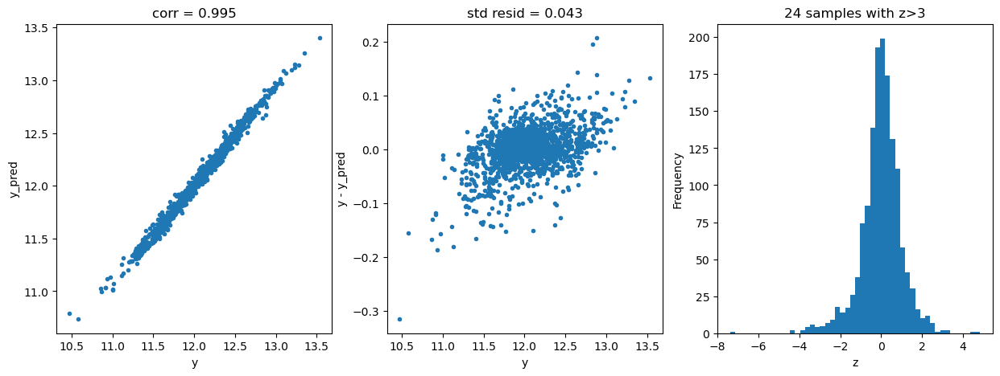

In [76]:
model = 'RandomForest'
opt_models[model] = RandomForestRegressor()

param_grid = {'n_estimators':[100,150,200],
              'max_features':[25,50,75],
              'min_samples_split':[2,4,6]}

opt_models[model], cv_score, grid_results = train_model(opt_models[model], param_grid=param_grid, 
                                              splits=5, repeats=1)

row = cv_score.to_frame().T               # Series -> 1-row DataFrame
row.index = [model]
score_models = pd.concat([score_models, row], axis=0)

Gradient Boosting

Fitting 5 folds for each of 27 candidates, totalling 135 fits
----------------------
GradientBoostingRegressor(max_depth=2, min_samples_split=6, n_estimators=350)
----------------------
score= 0.9728924003292322
rmse= 0.06384788002232118
cross_val: mean= 0.10357736913490459 , std= 0.009420874749178904


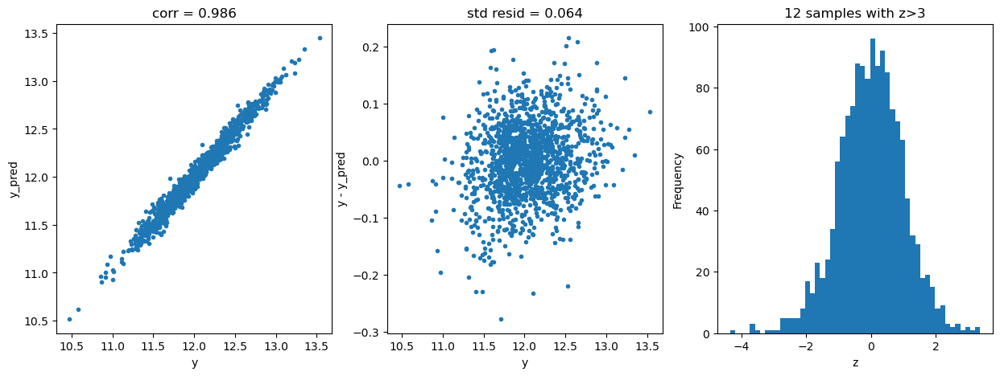

In [78]:
model = 'GradientBoosting'
opt_models[model] = GradientBoostingRegressor()

param_grid = {'n_estimators':[150,250,350],
              'max_depth':[1,2,3],
              'min_samples_split':[5,6,7]}

opt_models[model], cv_score, grid_results = train_model(opt_models[model], param_grid=param_grid, 
                                              splits=splits, repeats=1)

row = cv_score.to_frame().T               # Series -> 1-row DataFrame
row.index = [model]
score_models = pd.concat([score_models, row], axis=0)

XGBoost

Fitting 5 folds for each of 15 candidates, totalling 75 fits
----------------------
XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=1,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=500,
             n_jobs=None, num_parallel_tree=None, ...)
----------------------
score= 0.9613399479604207
rmse= 0.07624865147635322
cross_val: mean= 0.10193221888051451 , std= 0.003946576859685517


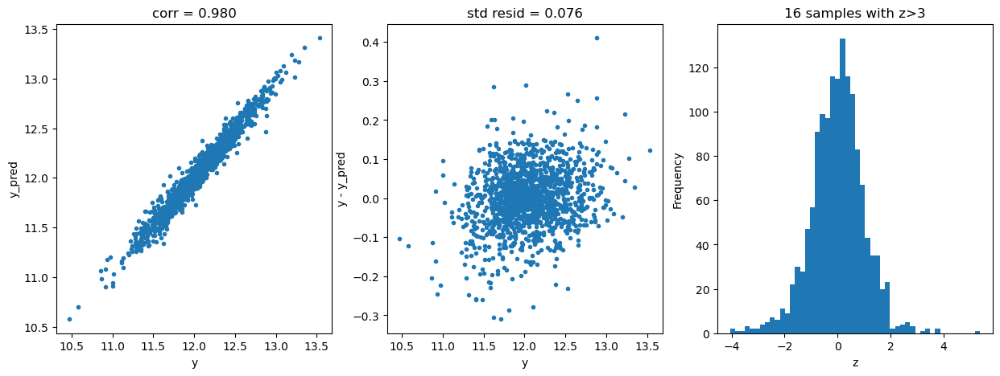

In [80]:
model = 'XGB'
opt_models[model] = XGBRegressor()

param_grid = {'n_estimators':[100,200,300,400,500],
              'max_depth':[1,2,3],
             }

opt_models[model], cv_score,grid_results = train_model(opt_models[model], param_grid=param_grid, 
                                              splits=splits, repeats=1)

row = cv_score.to_frame().T               # Series -> 1-row DataFrame
row.index = [model]
score_models = pd.concat([score_models, row], axis=0)

## Compare Models

Roughly speaking the linear regression models perform best, then support vector machines, then the tree-based ensembles and KNeighbors brings up the rear. The worst performing models, KNeighbors and RandomForest, have some correlation between the residuals and the sale price, which indicates there are relationships in the features those models haven't been able to identify as well as the others. 

Most of the features in the data have a close to linear relationship with sale price (at least the most important ones), so maybe it's not surprising to see linear regression on top, even if they are the simplest, most restrictive models. The feature engineering we did was also with the limitations of linear regression in mind. However, we have seen in other people's notebooks that XGBoost tends to be better than, or at least similar to, the linear models. 

,mean,std
ElasticNet,0.092728,0.004686
Lasso,0.093158,0.004492
Ridge,0.095484,0.004647
SVR,0.099252,0.003538
XGB,0.101932,0.003947
GradientBoosting,0.103577,0.009421
LinearSVR,0.106379,0.010035
RandomForest,0.117400,0.006016
KNeighbors,0.183669,0.006900


<Axes: >

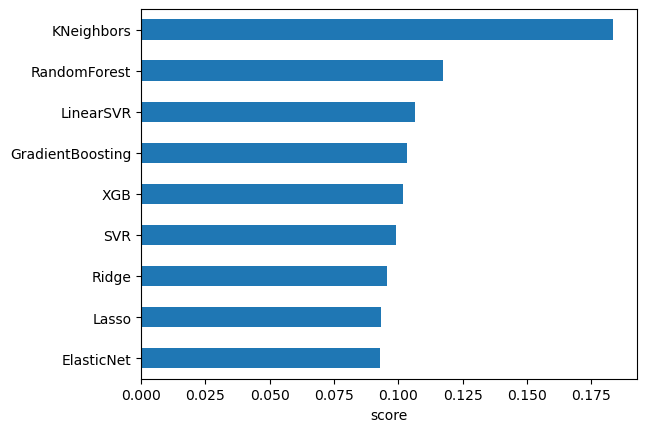

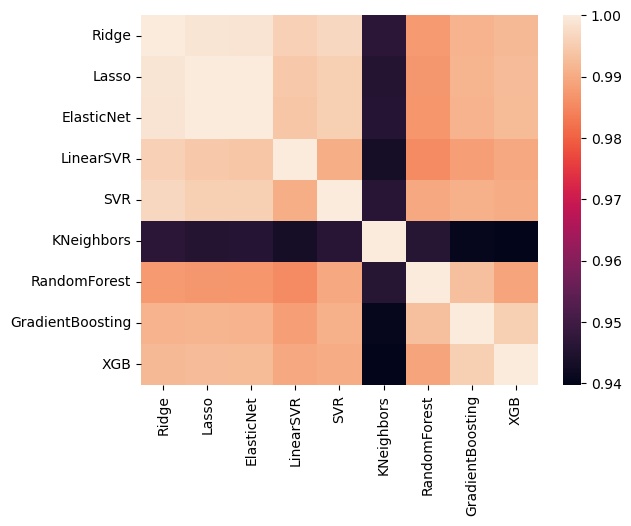

In [82]:
X,y = get_training_data()

Y_models = pd.DataFrame(index=y.index)    

for key, model in opt_models.items():
    Y_models[key] = model.predict(X)

corr_models = pd.DataFrame(Y_models).corr()

score_models = score_models.sort_values(by='mean')

display(score_models)
score_models['mean'].plot.barh()
plt.xlabel('score')

plt.figure()
sns.heatmap(corr_models)

## Best Model: ElasticNet

ElasticNet and Lasso give similar results, sometimes Lasso gives a better cross-validation score, sometimes ElasticNet. ElasticNet tended to give us a slightly better leaderboard score so we stuck with that for our final model. 

Below is a summary of the coefficients of the optimized ElasticNet model. About half the features are removed (have zero coefficient), most being dummy variables for certain categorical feature values. Some of the new features we created end up being removed, but others appear among the most important terms - such as TotalAreaSF and BsmtGLQSF. There are no big surprises - the features that end up appearing here are generally the same ones that stuck out in the EDA.

---------------------------------------
142 zero coefficients
109 non-zero coefficients
---------------------------------------
Intercept:  10.248019478666313
---------------------------------------
Top 20 contributers to increased price:
---------------------------------------
TotalAreaSF             0.625171
OverallQual             0.416118
OverallCond             0.305443
1stFlrSF                0.302871
LotArea                 0.255779
YearBuilt               0.229452
2ndFlrSF                0.219756
LivingAreaSF            0.201229
Functional              0.181635
Neighborhood_StoneBr    0.105104
FullBath                0.100524
TotalBsmtSF             0.096160
Neighborhood_Crawfor    0.094477
RoofMatl_WdShngl        0.086722
Exterior1st_BrkFace     0.085306
OpenPorchSF             0.078687
GarageCars              0.074657
BsmtGLQSF               0.074161
GrLivArea               0.070967
KitchenQual             0.070201
dtype: float64
---------------------------------------
Top 10

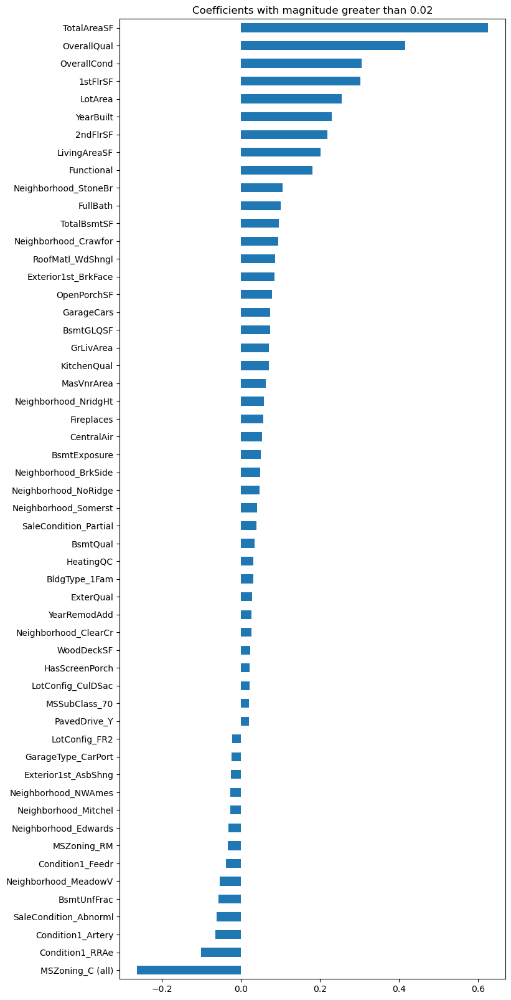

In [84]:
# get coefficients from previously optimised ElasticNet model
en_coefs = pd.Series(opt_models['ElasticNet'].coef_,index=X.columns)

plt.figure(figsize=(8,20))
en_coefs[en_coefs.abs()>0.02].sort_values().plot.barh()
plt.title('Coefficients with magnitude greater than 0.02')

print('---------------------------------------')
print(sum(en_coefs==0),'zero coefficients')
print(sum(en_coefs!=0),'non-zero coefficients')
print('---------------------------------------')
print('Intercept: ',opt_models['ElasticNet'].intercept_)
print('---------------------------------------')
print('Top 20 contributers to increased price:')
print('---------------------------------------')
print(en_coefs.sort_values(ascending=False).head(20))
print('---------------------------------------')
print('Top 10 contributers to decreased price:')
print('---------------------------------------')
print(en_coefs.sort_values(ascending=True).head(10))
print('---------------------------------------')
print('Zero coefficients:')
print('---------------------------------------')
print(en_coefs[en_coefs==0].index.sort_values().tolist())

## Find Useful Interactions

We decided to try adding some interaction terms to the model, i.e. one feature multiplied by another. Intuitively it seems like these could be important for determining sale price, a small property finished to a high quality may be worth as much as a larger property that needs a lot of work doing to it, for example. 

Including all polynomial terms up to 2nd order ends up giving more than 30,000 features, far more than the number of training examples and unlikely to give good results if we try to fit a model using that. Instead, we decided to only include features that meet these criteria: 

- only inclue interaction terms (e.g., TotalAreaSF*OverallQual), exclude squared terms (e.g. TotalAreaSF*TotalAreaSF)
- Only include features with non-zero coefficients in the optimized ElasticNet model above
- Only include features with more than 2 unique values (exclude all binary features and dummy variables)

This reduces the number of features in the new model to around 700. Excluding the dummy variables unfortunately means interactions with categorical variables like Neighborhood are not included. We suspect some of these could be important, but to include them in the model an approach other than one-hot encoding should probably be used, so we don't end up with thousands of columns that are ones and zeros multiplied together. 

The code below fits a Lasso model to the new training data with interactions included, and prints some stats about the resulting coefficients

Fitting 5 folds for each of 9 candidates, totalling 45 fits
----------------------
Lasso(alpha=0.0001, max_iter=100000)
----------------------
score= 0.9439488418874954
rmse= 0.09181068870672583
cross_val: mean= 0.10233427097127372 , std= 0.0051989138781714074
------------------------
492 zero coefficients
104 non-zero coefficients
54 non-zero interaction terms.
------------------------
Features with largest coefficients:
------------------------
33                    TotalAreaSF,
289         Fireplaces, YearBuilt,
24                    OverallCond,
388      GarageQual, KitchenAbvGr,
19                        LotArea,
9                      Fireplaces,
333       Functional, OverallQual,
14                     GarageQual,
336         Functional, YearBuilt,
36         1stFlrSF, BsmtExposure,
34                   LivingAreaSF,
32                    BsmtUnfFrac,
267        FireplaceQu, BsmtGLQSF,
15                      GrLivArea,
40            1stFlrSF, ExterQual,
86           2ndFlrSF, M

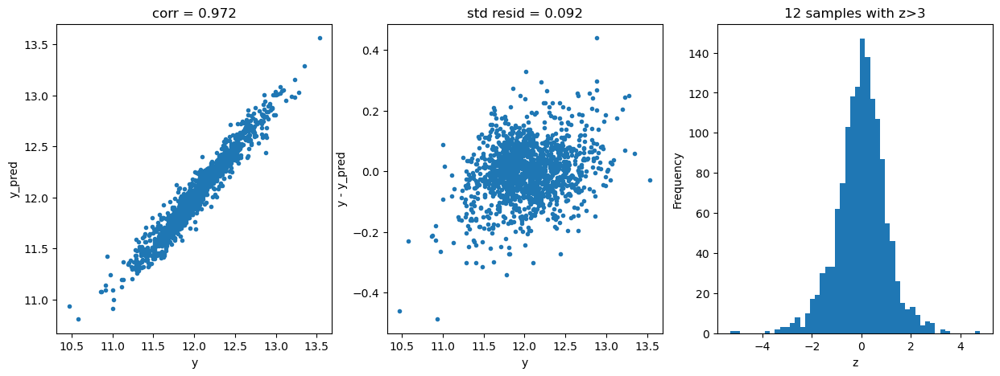

In [86]:
X,y=get_training_data()

#restrict to non-binary columns with non-zero coefficients only
select_cols = [col for col in X.columns if X[col].nunique()>2 and en_coefs[col]!=0]
X = X[select_cols]

# add interaction terms (x1*x2, but not x1**2) for all remaining features
poly = PolynomialFeatures(interaction_only=True)
X_poly = poly.fit_transform(X,y)
X_poly = pd.DataFrame(X_poly,index=y.index)

# save info on which features contribute to each term in X_poly
powers = pd.DataFrame(poly.powers_,columns=X.columns)

s = np.where(powers>0, pd.Series(X.columns)+', ', '')
poly_terms = pd.Series([''.join(x).strip() for x in s])

# fit a new model with the interaction terms
alph_range = np.arange(5e-5,2e-4,2e-5)
param_grid = {'alpha': np.arange(1e-4,1e-3,1e-4),
              'max_iter':[100000]}

model,_,_ = train_model(Lasso(), X=X_poly,y=y,param_grid=param_grid, 
                                              splits=splits, repeats=1)

poly_coefs = pd.Series(model.coef_)

print('------------------------')
print(sum(poly_coefs==0),'zero coefficients')
print(sum(poly_coefs!=0),'non-zero coefficients')
print(len(poly_coefs[(powers.sum(axis=1)==2) & (poly_coefs>0)]),'non-zero interaction terms.')
print('------------------------')
print('Features with largest coefficients:')
print('------------------------')
print(poly_terms[poly_coefs.abs().sort_values(ascending=False).index[:30]])
print('------------------------')

## Refit with Important Interactions

Using the model above directly ends up giving a worse cross-validation score. So we had to restrict ourselves to an even more limited range of interaction terms. 

Above we can see that the number of non-zero coefficients in the new fitted model is actually about the same as before without the interaction terms - the vast majority of the new interactions we ended up being removed from the model. However, more promisingly about half of the non-zero coefficients correspond to interactions, so about 60 of the original features have been replaced in the model by interactions. And 20 out of the 30 largest coefficients are interactions. Some of the interactions that are important make sense, such as BsmtQual*OverallQual, or KitchenQual*TotalAreaSF. Others maybe not so much, like Fireplaces*YearBuilt which is now the 3rd most important feature. 

We decided to create a new model including the interactions with the top 20 largest coefficients, irrespective of whether they were interactions that seemed logical. The code below adds these interactions to the train and test data then fits a new ElasticNet model.

In [88]:
# sort coefficients by magnitude, and calculate no. features that contribute
# to the polynomial term that coefficient represents.
poly_coef_nterms = powers.loc[poly_coefs.abs().sort_values(ascending=False).index].sum(axis=1)

# extract n_ints top interactions (interactions have 2 non-zero features in the powers vector)
n_ints = 20
top_n_int_idx = poly_coef_nterms[poly_coef_nterms==2].head(n_ints).index

# create a column for each of the top n_ints interactions in df_model
for idx in top_n_int_idx:
    # extract names of columns to multiply
    int_terms = powers.loc[idx]
    int_terms = int_terms[int_terms==1].index    
    term1 = int_terms[0]
    term2 = int_terms[1]
    
    # create interaction column
    df_model[term1+'_x_'+term2] = scale_minmax(df_model[term1]*df_model[term2])

# have a look at the new columns
display(df_model[df_model.columns[df_model.columns.str.contains('_x_')]].head(5))

,Fireplaces_x_YearBuilt,GarageQual_x_KitchenAbvGr,Functional_x_OverallQual,Functional_x_YearBuilt,1stFlrSF_x_BsmtExposure,FireplaceQu_x_BsmtGLQSF,1stFlrSF_x_ExterQual,2ndFlrSF_x_MasVnrArea,OverallCond_x_YearRemodAdd,Functional_x_TotalBsmtSF,KitchenQual_x_TotalAreaSF,BsmtQual_x_OverallQual,BsmtQual_x_TotalBsmtSF,FullBath_x_LotShape,BsmtExposure_x_Functional,2ndFlrSF_x_YearRemodAdd,OverallCond_x_BsmtUnfFrac,YearBuilt_x_YrSold,ExterCond_x_FireplaceQu,BsmtExposure_x_LivingAreaSF
Id,,,,,,,,,,,,,,,,,,,,
1,0.000000,0.375,0.666667,0.911386,0.090717,0.000000,0.241912,0.067633,0.432041,0.292894,0.352076,0.533333,0.234315,0.500000,0.25,0.425658,0.087617,0.455693,0.000,0.160555
2,0.213044,0.375,0.555556,0.614467,0.543162,0.000000,0.181054,0.000000,0.305795,0.403763,0.170465,0.444444,0.323011,0.400000,1.00,0.000000,0.196910,0.153617,0.375,0.611193
3,0.307529,0.375,0.666667,0.886981,0.197969,0.090898,0.263959,0.056686,0.421100,0.311392,0.368513,0.533333,0.249114,0.333333,0.50,0.420708,0.235870,0.443491,0.375,0.308521
4,0.058455,0.375,0.666667,0.168599,0.104027,0.000000,0.138702,0.000000,0.128163,0.263161,0.374306,0.400000,0.157896,0.133333,0.25,0.111779,0.357143,0.000000,0.500,0.137489
5,0.303350,0.375,0.777778,0.874929,0.373365,0.122506,0.331880,0.148916,0.399546,0.373336,0.430831,0.622222,0.298669,0.333333,0.75,0.485370,0.213974,0.437465,0.375,0.531361


Fitting 25 folds for each of 81 candidates, totalling 2025 fits
----------------------
ElasticNet(alpha=0.0002, l1_ratio=0.9, max_iter=100000)
----------------------
score= 0.9584089437730683
rmse= 0.07908623936911058
cross_val: mean= 0.09045715521481335 , std= 0.003974192039836444
------------------------
138 zero coefficients
133 non-zero coefficients
--------------------------
Interaction Coefficients:
--------------------------
Functional_x_OverallQual       0.318892
BsmtQual_x_TotalBsmtSF         0.201373
1stFlrSF_x_BsmtExposure        0.196352
KitchenQual_x_TotalAreaSF      0.132606
Functional_x_YearBuilt         0.096800
OverallCond_x_BsmtUnfFrac      0.086297
2ndFlrSF_x_YearRemodAdd        0.086076
1stFlrSF_x_ExterQual           0.080797
FullBath_x_LotShape            0.069521
YearBuilt_x_YrSold             0.048893
FireplaceQu_x_BsmtGLQSF        0.046529
BsmtQual_x_OverallQual         0.036511
Functional_x_TotalBsmtSF       0.012318
BsmtExposure_x_LivingAreaSF    0.008475
Over

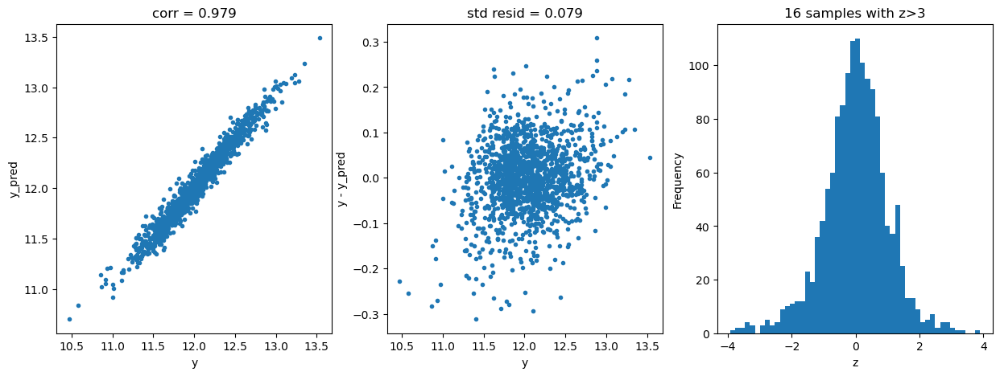

In [89]:
# fit a new model including the added interaction terms
en_int = ElasticNet()
alph_range = np.arange(5e-5,5e-4,2e-5)
param_grid = {'alpha': np.arange(1e-4,1e-3,1e-4),
              'l1_ratio': np.arange(0.1,1.0,0.1),
              'max_iter':[100000]}

en_int, cv_score, grid_results = train_model(en_int, param_grid=param_grid, 
                                              splits=splits, repeats=repeats)

X,y=get_training_data()
en_int_coef = pd.Series(en_int.coef_,index=X.columns)
print('------------------------')
print(sum(en_int_coef==0),'zero coefficients')
print(sum(en_int_coef!=0),'non-zero coefficients')
print('--------------------------')
print('Interaction Coefficients:')
print('--------------------------')
print(en_int_coef[en_int_coef.index.str.contains('_x_')].sort_values(ascending=False))
print('---------------------------------------')
print('Top 10 contributers to increased price:')
print('---------------------------------------')
print(en_int_coef.sort_values(ascending=False).head(10))
print('---------------------------------------')
print('Top 5 contributers to decreased price:')
print('---------------------------------------')
print(en_int_coef.sort_values(ascending=True).head(5))
print('---------------------------------------')

## Predict SalePrice for the Test Data

The ElasticNet model including the top 20 interactions gives a better cross-validation score than the original models, and this is the final model we use. 

All that's left to do to predict the sale prices for the test data, create the submissions file, and submit to kaggle.

below NOT RUN

In [91]:
def predict_test(model):
    # get test data
    X_test = get_test_data()

    # predict SalePrices
    y_test = model.predict(X_test)

    #revert log transformation
    y_test = np.exp(y_test)

    # make a data frame suitable for creating submission files0.11571
    y_test = pd.DataFrame(y_test,index=X_test.index)
    y_test.columns = ['SalePrice']
    
    return y_test

<Axes: ylabel='Frequency'>

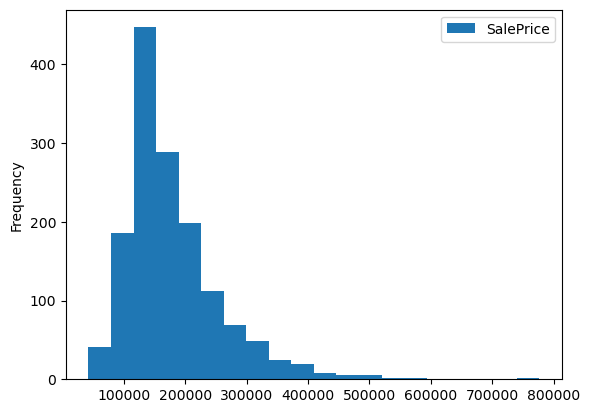

In [92]:
# predict sale prices
y_test = predict_test(en_int)

# make submission file
y_test.to_csv('ElasticNet.csv')

# overview of what sale prices were predicted
y_test.plot.hist(bins=20)